# 03 · Disponibilização — Camada semântica, análises e métricas

**Camada 3 do ETL — Disponibilização.** É o notebook mais importante do projeto: transforma a
camada de tratamento em um **modelo dimensional (fatos e dimensões)** pronto para o Power BI,
investiga as hipóteses com estatística e gráficos, treina um **modelo de alerta precoce** e exporta
as **métricas** que sustentam o pitch.

| | |
|---|---|
| **Entrada** | `data/02_tratamento/**` |
| **Saída** | `data/03_disponibilizacao/*.csv` (separador `;`, decimal `,`, UTF-8) e `reports/figures/*.png` |

## A pergunta
**O clima (temperatura, chuva, umidade) antecipa a explosão de casos de dengue?** Se sim, dá para
construir uma CitizenTech que avise prefeituras e moradores **antes** do pico — quando ainda há tempo
de eliminar criadouros.

## Hipóteses investigadas
| # | Hipótese | Técnica |
|---|---|---|
| H1 | Os casos se concentram no 1º semestre (verão/outono chuvoso) | participação por semana + qui-quadrado de aderência |
| H2 | Chuva e calor **antecedem** os casos em algumas semanas | correlação de Spearman defasada (0–16 semanas), por município |
| H3 | Existe uma **faixa ótima de temperatura** para a transmissão | faixas de temperatura × risco + Kruskal-Wallis / Mann-Whitney |
| H4 | Mais chuva acumulada aumenta o risco — até um limite | faixas de chuva × risco + Kruskal-Wallis |
| H5 | Anos com início **mais quente que o normal** são mais epidêmicos (ex.: 2024) | anomalias município-ano + Spearman |
| H6 | **Idosos** têm maior risco de agravamento e morte | letalidade/hospitalização por faixa etária + qui-quadrado |
| H7 | A troca do **sorotipo** predominante acompanha anos epidêmicos (fator não climático) | composição de sorotipos por ano |
| H8 | Municípios em **extrema pobreza** têm incidência diferente | Mann-Whitney, geral e por região |
| H9 | Incluir o clima **melhora a previsão** de semanas de alta transmissão | regressão logística, validação temporal, AUC/AP |

## Modelo dimensional (Power BI)
```
                    dim_tempo_semana ──┐            ┌── dim_estacao
                                       │            │
 dim_uf ── dim_municipio ──┬── fato_dengue_semanal  └── fato_clima_semanal_estacao
                           ├── fato_dengue_clima_semanal (+ alerta)
                           └── fato_dengue_anual_municipio ── dim_ano

 dim_ano ── fato_perfil_anual        fato_gravidade_faixa_etaria
 métricas: metricas_kpis · resultados_hipoteses · metricas_defasagem_clima · metricas_risco_temperatura
           metricas_risco_chuva · metricas_modelo_alerta · metricas_niveis_alerta · dicionario_dados
```

In [1]:
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, brier_score_loss, roc_auc_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from IPython.display import Markdown, display

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "config.py").exists())
sys.path.insert(0, str(ROOT / "src"))

import epi  # noqa: E402
import viz  # noqa: E402
from config import ANO_FIM, ANO_INICIO, CSV_POWERBI, DISPONIBILIZACAO, FIGURAS, TRATAMENTO, UF_POR_CODIGO  # noqa: E402

warnings.filterwarnings("ignore", category=RuntimeWarning)
viz.aplicar_estilo()
SAIDA = DISPONIBILIZACAO
SAIDA.mkdir(parents=True, exist_ok=True)
T = TRATAMENTO
FONTE_SINAN = "Fonte: SINAN/DATASUS (casos prováveis, local de residência); SVS/IBGE (população)."
FONTE_CLIMA = "Fontes: SINAN/DATASUS; INMET (estações automáticas); SVS/IBGE."

exportados: list[tuple[str, int, int]] = []
hipoteses: list[dict] = []


def exportar(df: pd.DataFrame, nome: str) -> pd.DataFrame:
    df = df.copy()
    floats = df.select_dtypes("float").columns
    df[floats] = df[floats].round(4)  # precisão suficiente e arquivos menores
    df.to_csv(SAIDA / f"{nome}.csv", **CSV_POWERBI)
    exportados.append((nome, len(df), df.shape[1]))
    return df


def sim_nao(s: pd.Series) -> pd.Series:
    return np.where(s.astype(bool), "Sim", "Não")


def registrar(id_, hipotese, metodo, estatistica, p_valor, efeito, resultado, interpretacao):
    limpa = lambda t: str(t).replace(";", " |")  # noqa: E731 — ';' é o separador do CSV
    estatistica, efeito, interpretacao = limpa(estatistica), limpa(efeito), limpa(interpretacao)
    hipoteses.append(dict(id=id_, hipotese=hipotese, metodo=metodo, estatistica=estatistica, p_valor=p_valor,
                          tamanho_efeito=efeito, resultado=resultado, interpretacao=interpretacao))


def p_fmt(p: float) -> str:
    return "< 0,001" if p < 0.001 else viz.fmt_br(p, 3)

## 1. Leitura da camada de tratamento e parâmetros analíticos

In [2]:
dengue = pd.read_parquet(T / "integrado" / "painel_dengue_semanal.parquet")
pdc = pd.read_parquet(T / "integrado" / "painel_dengue_clima_semanal.parquet")
municipios = pd.read_parquet(T / "datasus" / "municipios.parquet")
estacoes = pd.read_parquet(T / "inmet" / "estacoes.parquet")
est_mun = pd.read_parquet(T / "integrado" / "estacao_municipio.parquet")
clima_est = pd.read_parquet(T / "inmet" / "inmet_semanal_estacao.parquet")
perfil = pd.read_parquet(T / "datasus" / "perfil_anual.parquet")
gravidade = pd.read_parquet(T / "datasus" / "gravidade_faixa_etaria.parquet")
semana_br = pd.read_parquet(T / "datasus" / "contexto_semana_brasil.parquet")

ULTIMA_SEMANA = int(dengue["id_semana"].max())
ULTIMO_ANO_COMPLETO = ANO_FIM - 1

**Parâmetros** (documentados aqui para que toda métrica seja reproduzível):

* **Semana de alta transmissão:** incidência semanal ≥ **15 casos por 100 mil hab.** O Ministério da
  Saúde classifica como *alta* a incidência anual ≥ 300/100 mil; diluída numa temporada de ~20
  semanas, isso equivale a ~15/100 mil por semana.
* **Classificação anual (MS):** baixa < 100; média 100–299; alta ≥ 300 casos/100 mil hab.
* **Amostra clima × dengue:** municípios com estação e **≥ 70% das semanas com temperatura válida**.
  Para correlações e modelo, também **≥ 50 mil habitantes** (em municípios pequenos, 1 caso já
  distorce a incidência).
* **Janela climática:** médias/somas móveis de **4 semanas**, defasadas **4 semanas** (ciclo do
  *Aedes* de ovo a adulto ~7–10 dias + incubação no mosquito ~8–12 dias + no ser humano ~4–7 dias).
* **Horizonte do alerta:** **8 semanas** (≈ 2 meses de antecedência para agir).
* As **4 últimas semanas publicadas** (atraso de notificação) ficam fora das análises.

In [3]:
LIMIAR_ALTA = 15.0
COBERTURA_MIN = 0.70
POP_MIN = 50_000
JANELA, DEFASAGEM = 4, 4
HORIZONTE = 8
ANO_CORTE_TREINO = 2022

cobertura = pdc.groupby("cod_municipio")["temp_media_c"].apply(lambda s: s.notna().mean())
pop_atual = municipios.set_index("cod_municipio")["populacao_2025"]
AMOSTRA = sorted(cobertura[cobertura >= COBERTURA_MIN].index)
AMOSTRA_50K = [c for c in AMOSTRA if pop_atual[c] >= POP_MIN]
print(f"Municípios com estação: {pdc.cod_municipio.nunique()} | com cobertura ≥ 70%: {len(AMOSTRA)} | "
      f"e ≥ 50 mil hab.: {len(AMOSTRA_50K)}")

Municípios com estação: 651 | com cobertura ≥ 70%: 346 | e ≥ 50 mil hab.: 168


## 2. Camada semântica — dimensões

In [4]:
MESES = ["Jan", "Fev", "Mar", "Abr", "Mai", "Jun", "Jul", "Ago", "Set", "Out", "Nov", "Dez"]
ESTACAO = {12: "Verão", 1: "Verão", 2: "Verão", 3: "Outono", 4: "Outono", 5: "Outono",
           6: "Inverno", 7: "Inverno", 8: "Inverno", 9: "Primavera", 10: "Primavera", 11: "Primavera"}
ultimas4 = sorted(dengue["id_semana"].unique())[-4:]

dim_tempo = epi.calendario(ANO_INICIO, ANO_FIM)
dim_tempo = dim_tempo[dim_tempo["id_semana"] <= ULTIMA_SEMANA].copy()
meio = dim_tempo["data_inicio"] + pd.Timedelta(days=3)
dim_tempo["mes_referencia"] = meio.dt.month
dim_tempo["nome_mes"] = dim_tempo["mes_referencia"].map(lambda m: MESES[m - 1])
dim_tempo["trimestre"] = (dim_tempo["mes_referencia"] - 1) // 3 + 1
dim_tempo["estacao_ano"] = dim_tempo["mes_referencia"].map(ESTACAO)
dim_tempo["periodo_sazonal"] = np.where(dim_tempo["semana_epi"] <= 22, "Alta temporada (SE 1–22)", "Baixa temporada (SE 23–53)")
dim_tempo["rotulo_semana"] = dim_tempo["ano_epi"].astype(str) + "/SE" + dim_tempo["semana_epi"].astype(str).str.zfill(2)
dim_tempo["dado_preliminar"] = sim_nao(dim_tempo["ano_epi"] == ANO_FIM)
dim_tempo["atraso_notificacao"] = sim_nao(dim_tempo["id_semana"].isin(ultimas4))
exportar(dim_tempo, "dim_tempo_semana")

dim_ano = pd.DataFrame({"ano": range(ANO_INICIO, ANO_FIM + 1)})
dim_ano["ano_parcial"] = sim_nao(dim_ano["ano"] == ANO_FIM)
dim_ano["rotulo_ano"] = dim_ano["ano"].astype(str).where(dim_ano["ano"] < ANO_FIM,
                                                          f"{ANO_FIM} (parcial até SE{ULTIMA_SEMANA % 100})")
exportar(dim_ano, "dim_ano")

dim_uf = pd.DataFrame([(k, *v) for k, v in UF_POR_CODIGO.items()], columns=["cod_uf", "sigla_uf", "nome_uf", "regiao"])
exportar(dim_uf, "dim_uf")

coords = est_mun.dropna(subset=["cod_municipio"]).groupby("cod_municipio").agg(
    qtd_estacoes=("codigo_wmo", "size"), latitude=("latitude", "mean"), longitude=("longitude", "mean"))
dim_mun = municipios.merge(coords, left_on="cod_municipio", right_index=True, how="left")
dim_mun["qtd_estacoes"] = dim_mun["qtd_estacoes"].fillna(0).astype(int)
dim_mun["possui_estacao_inmet"] = sim_nao(dim_mun["qtd_estacoes"] > 0)
dim_mun["amostra_clima"] = sim_nao(dim_mun["cod_municipio"].isin(AMOSTRA))
dim_mun["municipio_uf"] = dim_mun["nome_municipio"] + "/" + dim_mun["sigla_uf"]
dim_mun["porte"] = pd.cut(dim_mun["populacao_2025"], [0, 20_000, 100_000, 500_000, np.inf],
                          labels=["Pequeno (até 20 mil)", "Médio (20–100 mil)", "Grande (100–500 mil)", "Metrópole (500 mil+)"])
dim_mun["capital"] = sim_nao(dim_mun["capital"])
dim_mun["extrema_pobreza"] = sim_nao(dim_mun["extrema_pobreza"])
dim_mun = dim_mun[["cod_municipio", "nome_municipio", "municipio_uf", "cod_uf", "sigla_uf", "nome_uf", "regiao",
                   "capital", "extrema_pobreza", "porte", "populacao_2025", "possui_estacao_inmet", "qtd_estacoes",
                   "amostra_clima", "latitude", "longitude"]]
exportar(dim_mun, "dim_municipio")

dim_est = estacoes.merge(est_mun[["codigo_wmo", "cod_municipio"]], on="codigo_wmo", how="left")
dim_est = dim_est[["codigo_wmo", "nome_estacao", "sigla_uf", "regiao", "cod_municipio", "latitude", "longitude",
                   "altitude", "data_fundacao", "primeiro_ano", "ultimo_ano", "semanas_validas_temp", "semanas_validas_precip"]]
exportar(dim_est, "dim_estacao")
pd.DataFrame(exportados, columns=["tabela", "linhas", "colunas"])

,tabela,linhas,colunas
0,dim_tempo_semana,671,13
1,dim_ano,13,3
2,dim_uf,27,4
3,dim_municipio,5571,16
4,dim_estacao,705,13


## 3. Camada semântica — fatos

In [5]:
dengue["alta_transmissao"] = dengue["incidencia_100k"] >= LIMIAR_ALTA

# Fato semanal: só semanas com casos (semanas sem casos não alteram somas; reduz o arquivo ~3x)
fato_sem = dengue.loc[dengue["casos"] > 0, ["id_semana", "cod_municipio", "casos", "incidencia_100k", "alta_transmissao"]].copy()
fato_sem["alta_transmissao"] = sim_nao(fato_sem["alta_transmissao"])
exportar(fato_sem, "fato_dengue_semanal")

# Fato anual por município
g = dengue.groupby(["cod_municipio", "ano_epi"])
anual = g.agg(casos=("casos", "sum"), populacao=("populacao", "first"),
              semanas_alta_transmissao=("alta_transmissao", "sum")).reset_index()
pico = dengue.loc[g["casos"].idxmax(), ["cod_municipio", "ano_epi", "semana_epi", "casos"]]
pico.columns = ["cod_municipio", "ano_epi", "semana_pico", "casos_semana_pico"]
anual = anual.merge(pico, on=["cod_municipio", "ano_epi"])
anual.loc[anual["casos"] == 0, ["semana_pico", "casos_semana_pico"]] = np.nan
anual["incidencia_100k"] = anual["casos"] / anual["populacao"] * 1e5
anual["nivel_incidencia"] = pd.cut(anual["incidencia_100k"], [-1, 100, 300, np.inf], right=False,
                                   labels=["Baixa (<100)", "Média (100–299)", "Alta (≥300)"])
anual["sigla_uf"] = anual["cod_municipio"].str[:2].map(lambda c: UF_POR_CODIGO[c][0])
anual["rank_incidencia_uf"] = anual.groupby(["ano_epi", "sigla_uf"])["incidencia_100k"].rank(ascending=False, method="min").astype("Int64")
anual = anual.rename(columns={"ano_epi": "ano"}).drop(columns="sigla_uf")
exportar(anual, "fato_dengue_anual_municipio")

# Fato clima semanal por estação
fato_clima = clima_est[["id_semana", "codigo_wmo", "precipitacao_mm", "precipitacao_max_diaria_mm", "dias_chuva",
                        "temp_media_c", "temp_max_media_c", "temp_min_media_c", "umidade_media_pct",
                        "n_dias_validos_temp", "n_dias_validos_precip"]]
fato_clima = fato_clima[fato_clima["id_semana"] <= ULTIMA_SEMANA]
exportar(fato_clima, "fato_clima_semanal_estacao")

# Fato perfil anual (formato longo) e gravidade por faixa etária
fato_perfil = perfil.copy()
fato_perfil["pct_no_ano"] = fato_perfil["casos"] / fato_perfil.groupby(["ano", "dimensao"])["casos"].transform("sum") * 100
exportar(fato_perfil, "fato_perfil_anual")

gv = gravidade.pivot_table(index=["faixa_etaria", "ordem_faixa"], columns=["dimensao", "categoria"], values="casos", aggfunc="sum")
fato_grav = pd.DataFrame({
    "casos": gv[("Evolução",)].sum(axis=1),
    "curas": gv[("Evolução", "Cura")],
    "obitos_dengue": gv[("Evolução", "Óbito por dengue")],
    "obitos_em_investigacao": gv[("Evolução", "Óbito em investigação")],
    "hospitalizados": gv[("Hospitalização", "Sim")],
    "hospitalizacao_informada": gv[("Hospitalização", "Sim")] + gv[("Hospitalização", "Não")],
}).reset_index()
fato_grav = fato_grav[fato_grav["faixa_etaria"] != "Ignorado/Branco"].sort_values("ordem_faixa")
fato_grav["letalidade_pct"] = fato_grav["obitos_dengue"] / fato_grav["casos"] * 100
fato_grav["obitos_por_100mil_casos"] = fato_grav["obitos_dengue"] / fato_grav["casos"] * 1e5
fato_grav["taxa_hospitalizacao_pct"] = fato_grav["hospitalizados"] / fato_grav["hospitalizacao_informada"] * 100
fato_grav["pct_casos"] = fato_grav["casos"] / fato_grav["casos"].sum() * 100
exportar(fato_grav, "fato_gravidade_faixa_etaria")
pd.DataFrame(exportados, columns=["tabela", "linhas", "colunas"])

,tabela,linhas,colunas
0,dim_tempo_semana,671,13
1,dim_ano,13,3
2,dim_uf,27,4
3,dim_municipio,5571,16
4,dim_estacao,705,13
5,fato_dengue_semanal,898923,5
6,fato_dengue_anual_municipio,72423,10
7,fato_clima_semanal_estacao,372465,11
8,fato_perfil_anual,507,6
9,fato_gravidade_faixa_etaria,11,12


## 4. Dimensionamento do problema

In [6]:
br_ano = anual.groupby("ano")[["casos", "populacao"]].sum()
br_ano["incidencia_100k"] = br_ano["casos"] / br_ano["populacao"] * 1e5
evo = perfil[perfil["dimensao"] == "Evolução"].pivot_table(index="ano", columns="categoria", values="casos")
obitos_ano = evo["Óbito por dengue"]
ano_rec = int(br_ano["incidencia_100k"].idxmax())
kpis = [
    ("Casos prováveis 2014–2026", br_ano["casos"].sum(), "casos", "Brasil, 2014 até a última semana publicada"),
    (f"Casos prováveis {ano_rec} (recorde)", br_ano.loc[ano_rec, "casos"], "casos", "Maior ano da série"),
    (f"Incidência {ano_rec}", br_ano.loc[ano_rec, "incidencia_100k"], "casos/100 mil hab.", "Brasil"),
    (f"Incidência média anual 2014–{ULTIMO_ANO_COMPLETO}", br_ano.loc[:ULTIMO_ANO_COMPLETO, "incidencia_100k"].mean(),
     "casos/100 mil hab.", "Média dos anos completos"),
    ("Óbitos por dengue 2014–2026", obitos_ano.sum(), "óbitos", "Evolução = óbito pelo agravo"),
    (f"Óbitos por dengue {ano_rec}", obitos_ano.loc[ano_rec], "óbitos", "Evolução = óbito pelo agravo"),
    ("Letalidade geral", obitos_ano.sum() / evo.sum(axis=1).sum() * 100, "% dos casos prováveis", "2014–2026"),
    (f"Municípios com incidência alta (≥300) em {ano_rec}",
     ((anual["ano"] == ano_rec) & (anual["incidencia_100k"] >= 300)).sum(), "municípios", "Classificação do MS"),
]
kpi_df = pd.DataFrame(kpis, columns=["indicador", "valor", "unidade", "descricao"])
kpi_df.assign(valor=kpi_df["valor"].map(lambda v: viz.fmt_br(v, 0 if v > 100 else 2)))

,indicador,valor,unidade,descricao
0,Casos prováveis 2014–2026,18.933.359,casos,"Brasil, 2014 até a última semana publicada"
1,Casos prováveis 2024 (recorde),6.564.894,casos,Maior ano da série
2,Incidência 2024,3.088,casos/100 mil hab.,Brasil
3,Incidência média anual 2014–2025,733,casos/100 mil hab.,Média dos anos completos
4,Óbitos por dengue 2014–2026,15.048,óbitos,Evolução = óbito pelo agravo
5,Óbitos por dengue 2024,6.337,óbitos,Evolução = óbito pelo agravo
6,Letalidade geral,"0,08",% dos casos prováveis,2014–2026
7,Municípios com incidência alta (≥300) em 2024,3.624,municípios,Classificação do MS


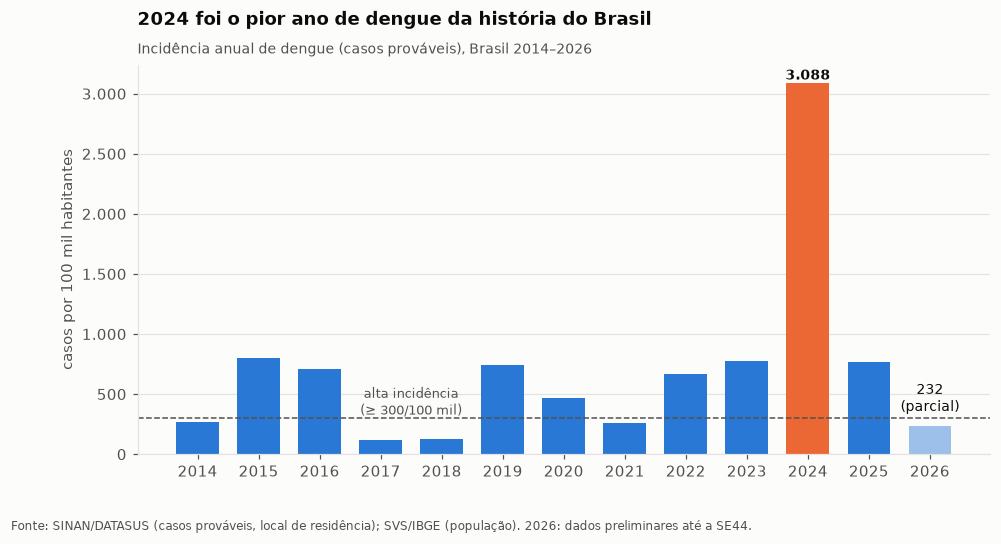

In [7]:
fig, ax = plt.subplots(figsize=(10, 4.6))
anos = br_ano.index.to_numpy()
cores = [viz.LARANJA if a == ano_rec else viz.AZUL for a in anos]
barras = ax.bar(anos, br_ano["incidencia_100k"], color=cores, width=0.7)
barras[-1].set_alpha(0.45)
for a in (ano_rec, anos[-1]):
    v = br_ano.loc[a, "incidencia_100k"]
    rot = viz.fmt_br(v) + ("\n(parcial)" if a == ANO_FIM else "")
    ax.text(a, max(v, 330) + 30, rot, ha="center", fontsize=9, fontweight="bold" if a == ano_rec else "normal")
ax.axhline(300, color=viz.TEXTO_2, lw=1, ls="--")
ax.text(2017.5, 330, "alta incidência\n(≥ 300/100 mil)", ha="center", fontsize=8.5, color=viz.TEXTO_2)
ax.set_xticks(anos)
ax.set_ylabel("casos por 100 mil habitantes")
ax.set_title(f"{ano_rec} foi o pior ano de dengue da história do Brasil")
viz.subtitulo(ax, f"Incidência anual de dengue (casos prováveis), Brasil 2014–{ANO_FIM}")
viz.milhar(ax)
viz.fonte(fig, FONTE_SINAN + f" {ANO_FIM}: dados preliminares até a SE{ULTIMA_SEMANA % 100}.")
viz.salvar(fig, "01_incidencia_anual_brasil", FIGURAS)
plt.show()

**Leitura:** a dengue no Brasil é **epidêmica e cíclica** — anos de explosão (2015, 2016, 2019,
2022–2024) se alternam com anos mais calmos. Em 2024 a incidência passou de 3.000 casos por 100 mil
habitantes, mais de 10 vezes o limiar de "alta incidência".

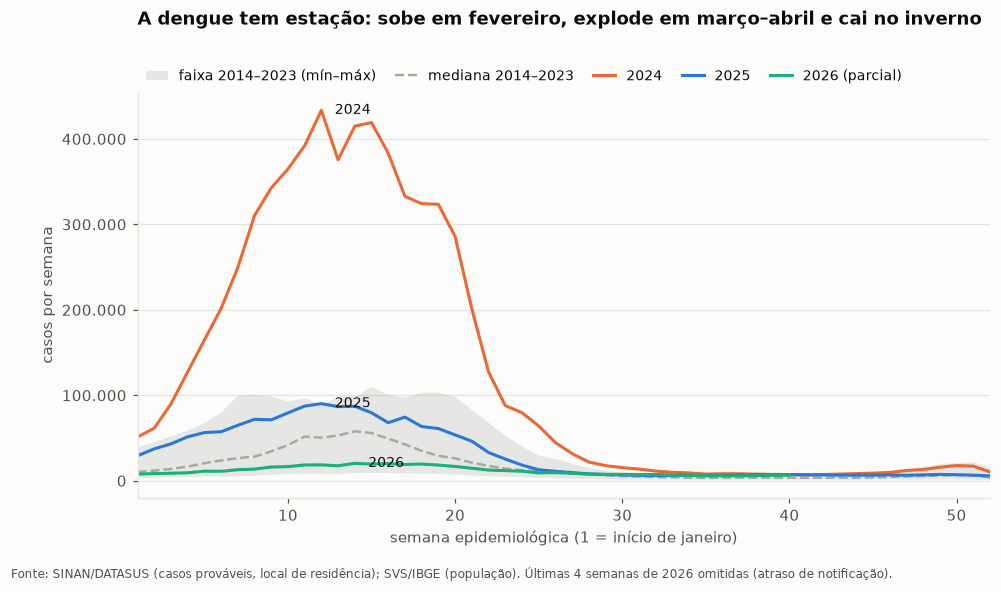

In [8]:
sb = semana_br[semana_br["semana_epi"] <= 52].pivot_table(index="semana_epi", columns="ano_epi", values="casos")
sb.loc[:, ANO_FIM] = sb[ANO_FIM].where(sb.index <= (ULTIMA_SEMANA % 100) - 4)
hist = sb.loc[:, :2023]
fig, ax = plt.subplots(figsize=(10, 4.8))
ax.fill_between(sb.index, hist.min(axis=1), hist.max(axis=1), color=viz.NEUTRO, alpha=0.25, lw=0,
                label="faixa 2014–2023 (mín–máx)")
ax.plot(sb.index, hist.median(axis=1), color=viz.NEUTRO, lw=1.6, ls="--", label="mediana 2014–2023")
for i, (a, cor) in enumerate([(2024, viz.LARANJA), (2025, viz.AZUL), (ANO_FIM, viz.AGUA)]):
    ax.plot(sb.index, sb[a], color=cor, label=str(a) + (" (parcial)" if a == ANO_FIM else ""))
    pk = sb[a].idxmax()
    ax.text(pk + 0.8, sb[a].max(), str(a), fontsize=9, color=viz.TEXTO, va="center")
ax.set_xlim(1, 52)
ax.set_xlabel("semana epidemiológica (1 = início de janeiro)")
ax.set_ylabel("casos por semana")
viz.milhar(ax)
ax.set_title("A dengue tem estação: sobe em fevereiro, explode em março–abril e cai no inverno", pad=44)
viz.legenda_topo(ax)
viz.fonte(fig, FONTE_SINAN + " Últimas 4 semanas de 2026 omitidas (atraso de notificação).")
viz.salvar(fig, "02_curva_epidemica_semanal", FIGURAS)
plt.show()

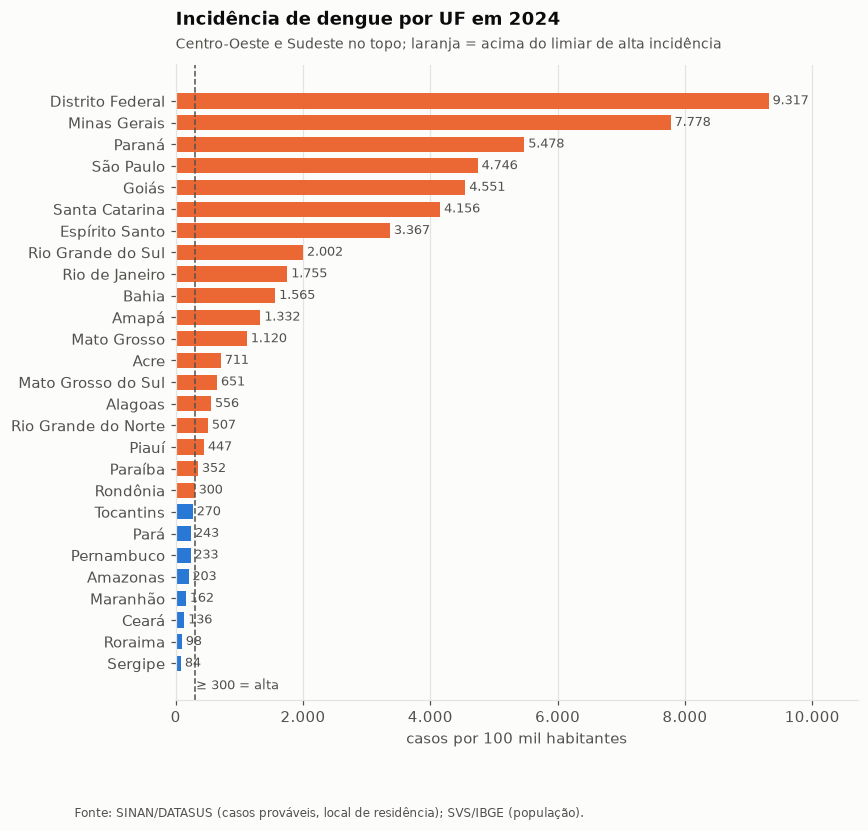

In [9]:
uf24 = (anual[anual["ano"] == ano_rec].assign(cod_uf=lambda d: d["cod_municipio"].str[:2])
        .groupby("cod_uf")[["casos", "populacao"]].sum())
uf24["incidencia"] = uf24["casos"] / uf24["populacao"] * 1e5
uf24 = uf24.join(dim_uf.set_index("cod_uf")).sort_values("incidencia")
fig, ax = plt.subplots(figsize=(8, 7.5))
cores = [viz.LARANJA if v >= 300 else viz.AZUL for v in uf24["incidencia"]]
ax.barh(uf24["nome_uf"], uf24["incidencia"], color=cores, height=0.7)
for y, v in enumerate(uf24["incidencia"]):
    ax.text(v + 60, y, viz.fmt_br(v), va="center", fontsize=8.5, color=viz.TEXTO_2)
ax.axvline(300, color=viz.TEXTO_2, lw=1, ls="--")
ax.text(320, -1.2, "≥ 300 = alta", fontsize=8.5, color=viz.TEXTO_2)
ax.set_xlim(0, uf24["incidencia"].max() * 1.15)
ax.grid(axis="y", visible=False)
ax.grid(axis="x", visible=True)
viz.milhar(ax, "x")
ax.set_xlabel("casos por 100 mil habitantes")
ax.set_title(f"Incidência de dengue por UF em {ano_rec}")
viz.subtitulo(ax, "Centro-Oeste e Sudeste no topo; laranja = acima do limiar de alta incidência")
viz.fonte(fig, FONTE_SINAN)
viz.salvar(fig, "03_ranking_uf", FIGURAS)
plt.show()

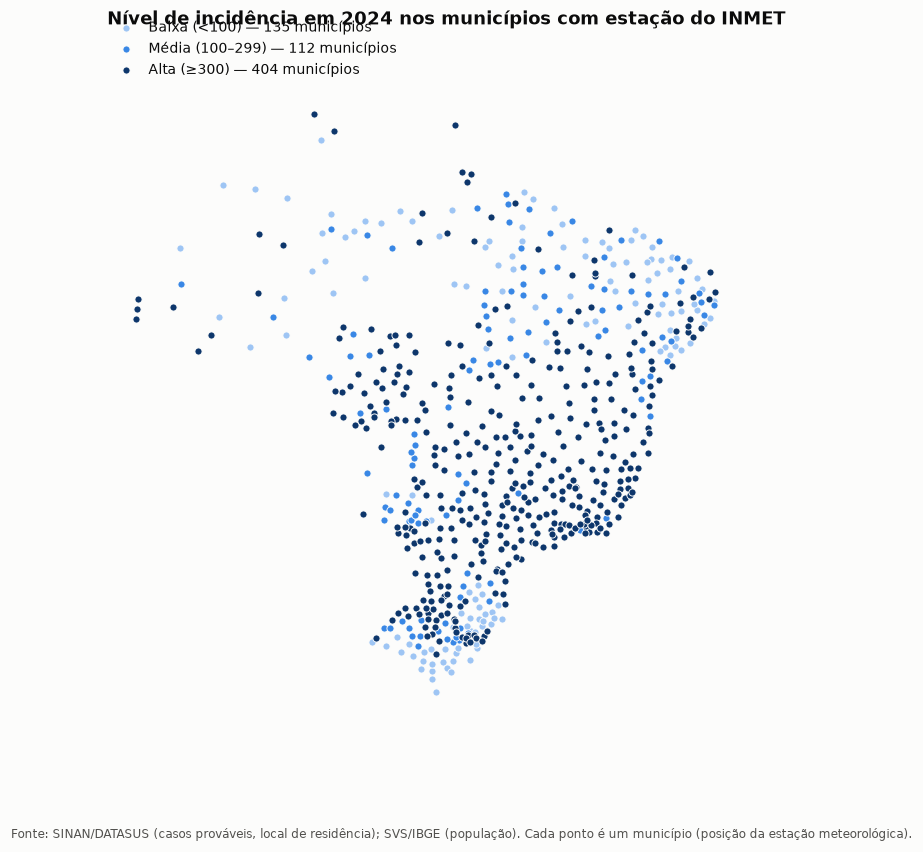

In [10]:
mapa = dim_mun.dropna(subset=["latitude"]).merge(anual[anual["ano"] == ano_rec][["cod_municipio", "nivel_incidencia"]])
niveis = {"Baixa (<100)": viz.SEQUENCIAL[1], "Média (100–299)": viz.SEQUENCIAL[3], "Alta (≥300)": viz.SEQUENCIAL[6]}
fig, ax = plt.subplots(figsize=(7.5, 7.5))
for nivel, cor in niveis.items():
    d = mapa[mapa["nivel_incidencia"] == nivel]
    ax.scatter(d["longitude"], d["latitude"], s=22, color=cor, edgecolor=viz.SUPERFICIE, linewidth=0.6,
               label=f"{nivel} — {len(d)} municípios")
ax.set_aspect("equal")
ax.grid(False)
ax.set_xticks([])
ax.set_yticks([])
for s in ax.spines.values():
    s.set_visible(False)
ax.set_title(f"Nível de incidência em {ano_rec} nos municípios com estação do INMET", pad=40)
viz.legenda_topo(ax, ncols=1)
viz.fonte(fig, FONTE_SINAN + " Cada ponto é um município (posição da estação meteorológica).")
viz.salvar(fig, "04_mapa_municipios_estacao", FIGURAS)
plt.show()

## 5. Persona — quem adoece e quem agrava (H6)

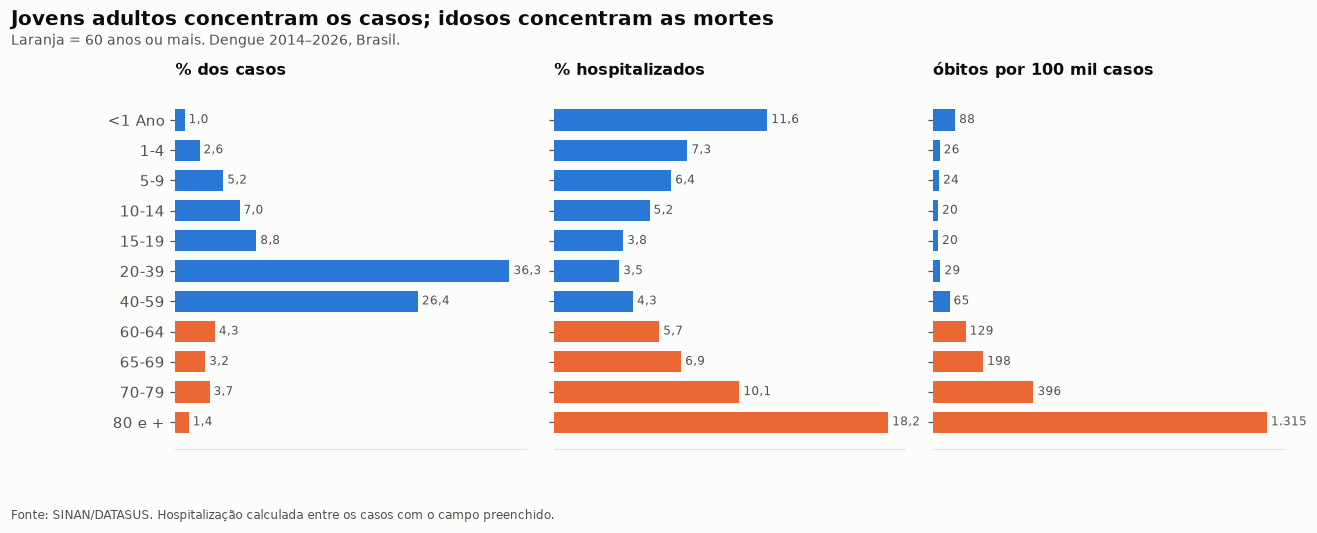

In [11]:
fg = fato_grav.set_index("faixa_etaria")
idosos = fg.index.isin(["60-64", "65-69", "70-79", "80 e +"])
fig, axs = plt.subplots(1, 3, figsize=(13, 4.2), sharey=True, gridspec_kw={"wspace": 0.08})
for ax, col, tit, fmt in [(axs[0], "pct_casos", "% dos casos", 1), (axs[1], "taxa_hospitalizacao_pct", "% hospitalizados", 1),
                          (axs[2], "obitos_por_100mil_casos", "óbitos por 100 mil casos", 0)]:
    ax.barh(fg.index, fg[col], color=[viz.LARANJA if i else viz.AZUL for i in idosos], height=0.7)
    for y, v in enumerate(fg[col]):
        ax.text(v, y, " " + viz.fmt_br(v, fmt), va="center", fontsize=8, color=viz.TEXTO_2)
    ax.set_title(tit, fontsize=10.5)
    ax.grid(axis="y", visible=False)
    ax.set_xticks([])
    ax.spines["left"].set_visible(False)
axs[0].invert_yaxis()
fig.suptitle("Jovens adultos concentram os casos; idosos concentram as mortes", x=0.01, ha="left",
             fontsize=13, fontweight="bold", y=1.06)
fig.text(0.01, 0.985, "Laranja = 60 anos ou mais. Dengue 2014–2026, Brasil.", fontsize=9, color=viz.TEXTO_2)
viz.fonte(fig, "Fonte: SINAN/DATASUS. Hospitalização calculada entre os casos com o campo preenchido.")
viz.salvar(fig, "05_persona_faixa_etaria", FIGURAS)
plt.show()

In [12]:
# H6 — qui-quadrado: faixa etária × (óbito por dengue vs. cura)
tab = fato_grav.set_index("faixa_etaria")[["obitos_dengue", "curas"]]
chi2, p, dof, _ = stats.chi2_contingency(tab)
cramer = np.sqrt(chi2 / (tab.to_numpy().sum() * (min(tab.shape) - 1)))
let = fato_grav.set_index("faixa_etaria")["obitos_por_100mil_casos"]
rr = let["80 e +"] / let["20-39"]
registrar("H6", "Idosos têm maior risco de morte por dengue", "Qui-quadrado (faixa etária × óbito/cura)",
          f"χ² = {viz.fmt_br(chi2)}; gl = {dof}", p_fmt(p), f"V de Cramér = {viz.fmt_br(cramer, 3)}; 80+ vs 20–39: {viz.fmt_br(rr, 1)}x",
          "Confirmada", f"A letalidade em 80+ anos é {viz.fmt_br(rr, 0)} vezes a de adultos de 20–39 anos.")
sexo = perfil[(perfil.dimensao == "Sexo") & (perfil.categoria != "Ignorado/Branco")].groupby("categoria")["casos"].sum()
raca = perfil[(perfil.dimensao == "Raça/cor") & (perfil.categoria != "Ignorado/Branco")].groupby("categoria")["casos"].sum()
print(f"χ² = {chi2:,.0f}, p {p_fmt(p)}, V de Cramér = {cramer:.3f} | risco relativo de morte 80+ vs 20–39: {rr:.1f}x")
print("Sexo (% entre informados):", (sexo / sexo.sum() * 100).round(1).to_dict())
print("Raça/cor (% entre informados):", (raca / raca.sum() * 100).round(1).to_dict())

χ² = 65,591, p < 0,001, V de Cramér = 0.066 | risco relativo de morte 80+ vs 20–39: 44.8x
Sexo (% entre informados): {'Feminino': 54.8, 'Masculino': 45.2}
Raça/cor (% entre informados): {'Amarela': 1.3, 'Branca': 48.9, 'Indígena': 0.3, 'Parda': 44.0, 'Preta': 5.5}


In [13]:
adultos = fg.loc[["20-39", "40-59"], "pct_casos"].sum()
h = fg["taxa_hospitalizacao_pct"]
display(Markdown(f"""
**Persona.** O caso típico é um **adulto de 20 a 59 anos** ({viz.fmt_br(adultos, 0)}% dos casos), um pouco mais
frequentemente **mulher** ({viz.fmt_br(sexo['Feminino'] / sexo.sum() * 100, 0)}%). Mas o risco de **agravamento**
está nas pontas da vida:

* **idosos** — a hospitalização sobe de {viz.fmt_br(h['20-39'], 1)}% (20–39 anos) para {viz.fmt_br(h['70-79'], 1)}% (70–79)
  e {viz.fmt_br(h['80 e +'], 1)}% (80+); a letalidade em 80+ anos é **{viz.fmt_br(rr, 0)} vezes** a de adultos de 20–39;
* **bebês < 1 ano** — {viz.fmt_br(h['<1 Ano'], 1)}% hospitalizados e letalidade {viz.fmt_br(let['<1 Ano'] / let['20-39'], 1)} vezes a de adultos jovens.

A solução precisa falar com dois públicos: quem **pega** (adultos — prevenção e eliminação de criadouros)
e quem **agrava** (idosos, bebês e seus cuidadores — sinais de alarme e busca rápida de atendimento).
"""))


**Persona.** O caso típico é um **adulto de 20 a 59 anos** (63% dos casos), um pouco mais
frequentemente **mulher** (55%). Mas o risco de **agravamento**
está nas pontas da vida:

* **idosos** — a hospitalização sobe de 3,5% (20–39 anos) para 10,1% (70–79)
  e 18,2% (80+); a letalidade em 80+ anos é **45 vezes** a de adultos de 20–39;
* **bebês < 1 ano** — 11,6% hospitalizados e letalidade 3,0 vezes a de adultos jovens.

A solução precisa falar com dois públicos: quem **pega** (adultos — prevenção e eliminação de criadouros)
e quem **agrava** (idosos, bebês e seus cuidadores — sinais de alarme e busca rápida de atendimento).


## 6. Clima × dengue

### 6.1 H1 — Sazonalidade: chuva e calor vêm antes dos casos
Três painéis com o **mesmo eixo de semanas** (e não um gráfico de dois eixos): clima médio dos
municípios da amostra e a distribuição dos casos ao longo do ano.

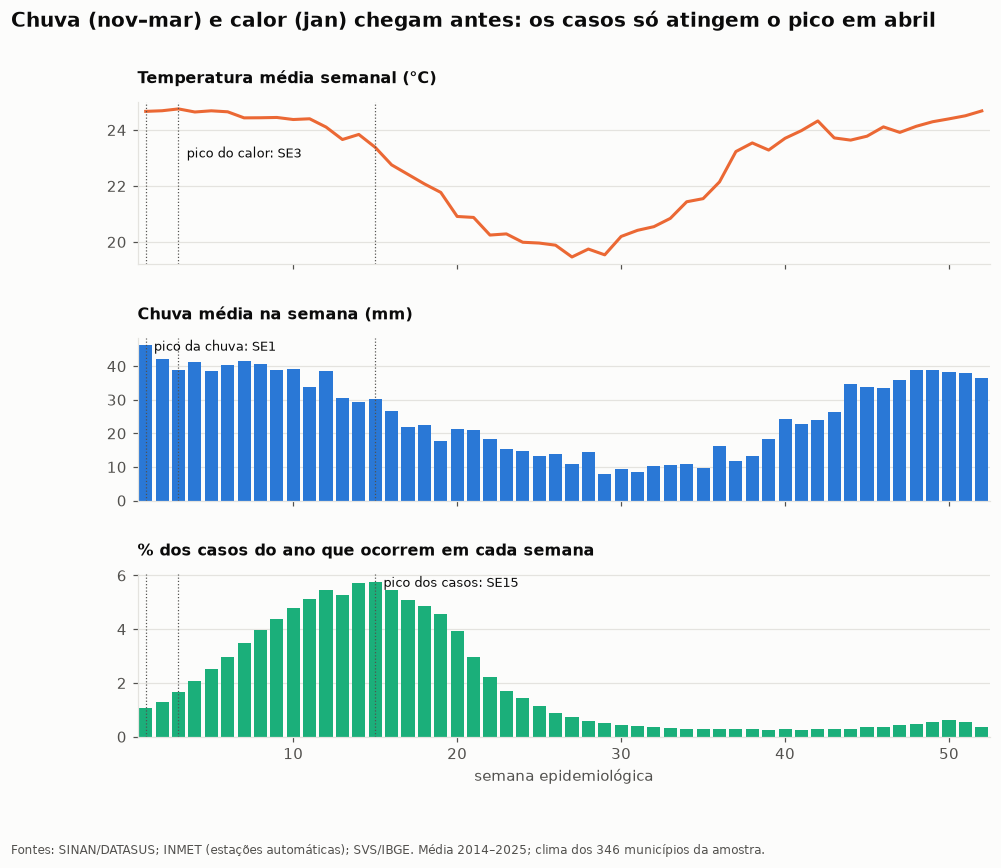

In [14]:
base = pdc[pdc["cod_municipio"].isin(AMOSTRA) & (pdc["ano_epi"] <= ULTIMO_ANO_COMPLETO) & (pdc["semana_epi"] <= 52)]
clim_sem = base.groupby("semana_epi")[["temp_media_c", "precipitacao_mm", "umidade_media_pct"]].mean()
casos_sem = semana_br[(semana_br.ano_epi <= ULTIMO_ANO_COMPLETO) & (semana_br.semana_epi <= 52)]
pct_sem = casos_sem.groupby("semana_epi")["casos"].sum()
pct_sem = pct_sem / pct_sem.sum() * 100
pico_chuva, pico_temp, pico_casos = clim_sem["precipitacao_mm"].idxmax(), clim_sem["temp_media_c"].idxmax(), pct_sem.idxmax()

fig, axs = plt.subplots(3, 1, figsize=(10, 7.5), sharex=True, gridspec_kw={"hspace": 0.45})
axs[0].plot(clim_sem.index, clim_sem["temp_media_c"], color=viz.LARANJA)
axs[0].set_title("Temperatura média semanal (°C)", fontsize=10.5)
axs[1].bar(clim_sem.index, clim_sem["precipitacao_mm"], color=viz.AZUL, width=0.8)
axs[1].set_title("Chuva média na semana (mm)", fontsize=10.5)
axs[2].bar(pct_sem.index, pct_sem.values, color=viz.AGUA, width=0.8)
axs[2].set_title("% dos casos do ano que ocorrem em cada semana", fontsize=10.5)
for ax, pk, rot in [(axs[0], pico_temp, "pico do calor"), (axs[1], pico_chuva, "pico da chuva"), (axs[2], pico_casos, "pico dos casos")]:
    for a in axs:
        a.axvline(pk, color=viz.TEXTO_2, lw=0.8, ls=":")
    ax.text(pk + 0.5, ax.get_ylim()[1] * 0.92, f"{rot}: SE{pk}", fontsize=8.5, color=viz.TEXTO)
axs[2].set_xlabel("semana epidemiológica")
axs[2].set_xlim(0.5, 52.5)
fig.suptitle("Chuva (nov–mar) e calor (jan) chegam antes: os casos só atingem o pico em abril", x=0.01, ha="left",
             fontsize=13, fontweight="bold", y=0.99)
viz.fonte(fig, FONTE_CLIMA + f" Média 2014–{ULTIMO_ANO_COMPLETO}; clima dos {len(AMOSTRA)} municípios da amostra.")
viz.salvar(fig, "06_sazonalidade_clima_casos", FIGURAS)
plt.show()

In [15]:
obs = casos_sem.groupby("semana_epi")["casos"].sum()
chi2_h1, p_h1 = stats.chisquare(obs)
pct_1o = obs.loc[1:22].sum() / obs.sum() * 100
registrar("H1", "Os casos se concentram no 1º semestre (SE 1–22)", "Qui-quadrado de aderência à distribuição uniforme",
          f"χ² = {viz.fmt_br(chi2_h1)}", p_fmt(p_h1), f"{viz.fmt_br(pct_1o, 1)}% dos casos em 42% das semanas",
          "Confirmada", f"Pico na SE{pico_casos}; chuva no pico na SE{pico_chuva} e calor na SE{pico_temp}.")
print(f"{pct_1o:.1f}% dos casos ocorrem nas SE 1–22 (42% das semanas). χ² = {chi2_h1:,.0f}, p {p_fmt(p_h1)}")

84.7% dos casos ocorrem nas SE 1–22 (42% das semanas). χ² = 18,576,775, p < 0,001


### 6.2 H2 — Defasagem: quantas semanas o clima antecede os casos?
Para cada município (≥ 50 mil hab.) calculamos a correlação de Spearman entre o clima da semana
*t − k* e a incidência (log) da semana *t*, para *k* = 0 a 16 semanas, e tiramos a mediana entre municípios.

Fazemos duas versões:
* **bruta** — inclui o ciclo sazonal (verão chuvoso → outono com casos);
* **anomalias** — subtrai de cada série a média histórica daquela semana do ano no município. Responde a
  uma pergunta mais difícil: *um clima fora do normal gera casos fora do normal?*

In [16]:
VARS = {"temp_media_c": "Temperatura", "precipitacao_mm": "Chuva", "umidade_media_pct": "Umidade"}
LAGS = range(0, 17)
c = pdc[pdc["cod_municipio"].isin(AMOSTRA_50K) & ~pdc["atraso_notificacao"]].sort_values(["cod_municipio", "id_semana"]).copy()
c["log_inc"] = np.log1p(c["incidencia_100k"])
for v in ["log_inc", *VARS]:
    c[v + "_anom"] = c[v] - c.groupby(["cod_municipio", "semana_epi"])[v].transform("mean")

linhas = []
for cod, d in c.groupby("cod_municipio"):
    for v in VARS:
        for k in LAGS:
            for tipo, x, y in [("bruta", d[v].shift(k), d["log_inc"]), ("anomalia", d[v + "_anom"].shift(k), d["log_inc_anom"])]:
                ok = x.notna() & y.notna()
                if ok.sum() >= 100:
                    r, pv = stats.spearmanr(x[ok], y[ok])
                    linhas.append((cod, VARS[v], k, tipo, r, pv))
corr = pd.DataFrame(linhas, columns=["cod_municipio", "variavel", "defasagem_semanas", "tipo", "rho", "p"])
defas = (corr.groupby(["variavel", "defasagem_semanas", "tipo"])
         .agg(rho_mediana=("rho", "median"), rho_p25=("rho", lambda s: s.quantile(0.25)), rho_p75=("rho", lambda s: s.quantile(0.75)),
              pct_municipios_positivos_signif=("rho", lambda s: 0), municipios=("rho", "size")).reset_index())
sig = corr.assign(pos=(corr["rho"] > 0) & (corr["p"] < 0.05)).groupby(["variavel", "defasagem_semanas", "tipo"])["pos"].mean() * 100
defas["pct_municipios_positivos_signif"] = defas.set_index(["variavel", "defasagem_semanas", "tipo"]).index.map(sig)
melhor = defas[defas.tipo == "bruta"].loc[lambda d: d.groupby("variavel")["rho_mediana"].idxmax()].set_index("variavel")
melhor[["defasagem_semanas", "rho_mediana", "pct_municipios_positivos_signif"]].round(3)

,defasagem_semanas,rho_mediana,pct_municipios_positivos_signif
variavel,,,
Chuva,10,0.195,66.667
Temperatura,14,0.284,83.929
Umidade,4,0.199,70.833


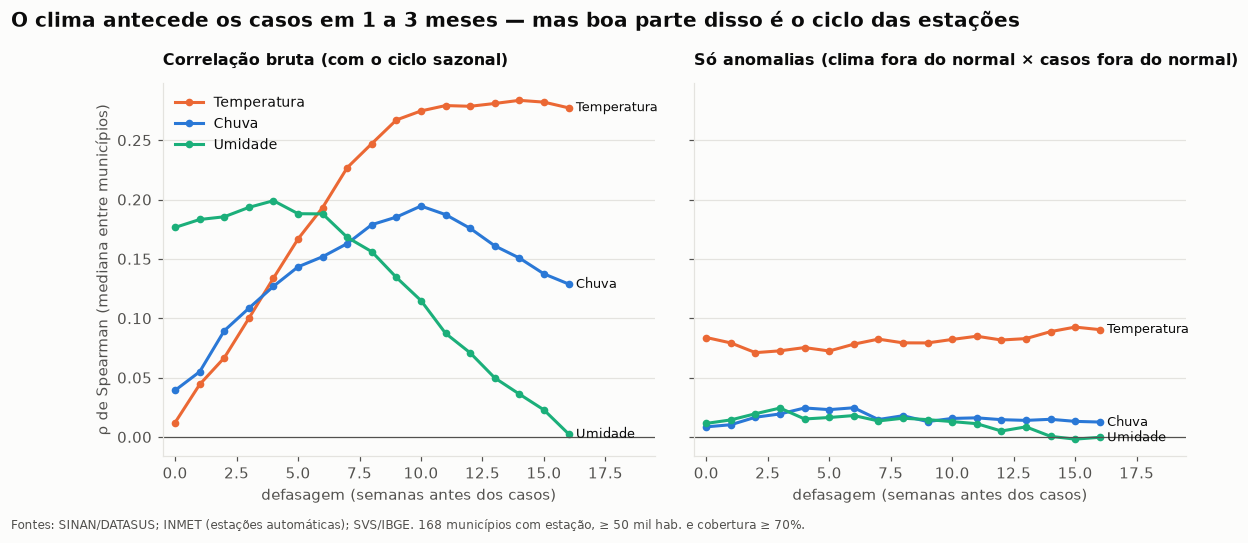

In [17]:
fig, axs = plt.subplots(1, 2, figsize=(12, 4.4), sharey=True, gridspec_kw={"wspace": 0.08})
for ax, tipo, tit in [(axs[0], "bruta", "Correlação bruta (com o ciclo sazonal)"),
                      (axs[1], "anomalia", "Só anomalias (clima fora do normal × casos fora do normal)")]:
    for i, v in enumerate(VARS.values()):
        d = defas[(defas.tipo == tipo) & (defas.variavel == v)]
        ax.plot(d["defasagem_semanas"], d["rho_mediana"], color=viz.CATEGORICA[[1, 0, 2][i]], marker="o", markersize=4, label=v)
        ax.text(d["defasagem_semanas"].iloc[-1] + 0.3, d["rho_mediana"].iloc[-1], v, fontsize=8.5, va="center")
    ax.axhline(0, color=viz.TEXTO_2, lw=0.8)
    ax.set_title(tit, fontsize=10.5)
    ax.set_xlabel("defasagem (semanas antes dos casos)")
    ax.set_xlim(-0.5, 19.5)
axs[0].set_ylabel("ρ de Spearman (mediana entre municípios)")
axs[0].legend(loc="upper left")
fig.suptitle("O clima antecede os casos em 1 a 3 meses — mas boa parte disso é o ciclo das estações",
             x=0.01, ha="left", fontsize=13, fontweight="bold", y=1.03)
viz.fonte(fig, FONTE_CLIMA + f" {len(AMOSTRA_50K)} municípios com estação, ≥ 50 mil hab. e cobertura ≥ 70%.")
viz.salvar(fig, "07_defasagem_clima_casos", FIGURAS)
plt.show()

In [18]:
anom = defas[defas.tipo == "anomalia"].groupby("variavel")["rho_mediana"].max()
mt = melhor.loc["Temperatura"]
# Teste: as correlações municipais na melhor defasagem da temperatura são > 0? (Wilcoxon unilateral)
rhos_t = corr[(corr.variavel == "Temperatura") & (corr.tipo == "bruta") & (corr.defasagem_semanas == mt.defasagem_semanas)]["rho"]
w_t = stats.wilcoxon(rhos_t, alternative="greater")
registrar("H2", "Chuva e calor antecedem os casos em algumas semanas",
          "Spearman defasado por município + Wilcoxon (ρ > 0)",
          f"ρ mediano: temperatura {viz.fmt_br(mt.rho_mediana, 2)} (k={int(mt.defasagem_semanas)}), "
          f"chuva {viz.fmt_br(melhor.loc['Chuva', 'rho_mediana'], 2)} (k={int(melhor.loc['Chuva', 'defasagem_semanas'])}), "
          f"umidade {viz.fmt_br(melhor.loc['Umidade', 'rho_mediana'], 2)} (k={int(melhor.loc['Umidade', 'defasagem_semanas'])})",
          p_fmt(w_t.pvalue), f"{viz.fmt_br(mt.pct_municipios_positivos_signif, 0)}% dos municípios com ρ > 0 significativo (temperatura)",
          "Confirmada (com ressalva)",
          f"Nas anomalias o sinal cai para ρ ≈ {viz.fmt_br(anom['Temperatura'], 2)} (temperatura) e "
          f"{viz.fmt_br(anom['Chuva'], 2)} (chuva): a maior parte da relação é sazonal.")

**Leitura:** na correlação bruta, a **umidade** responde mais rápido (pico em ~1 mês), a **chuva** em
~2 meses e a **temperatura** em ~3 meses — coerente com o ciclo verão-chuvoso → outono-epidêmico.
Quando removemos o ciclo sazonal (painel direito), o sinal fica **fraco**: só a temperatura mantém
uma correlação positiva e estável. Conclusão honesta: o clima **marca o calendário** da dengue; a
**intensidade** de cada ano depende também de outros fatores (imunidade da população, sorotipo
circulante, controle vetorial). Por isso o alerta deve combinar clima **e** vigilância de casos.

### 6.3 H3 e H4 — Faixa ótima de temperatura e efeito da chuva
Clima medido na janela de 4 semanas que termina 4 semanas antes da semana avaliada. Métrica de risco:
**% de semanas de alta transmissão** (≥ 15 casos/100 mil hab.).

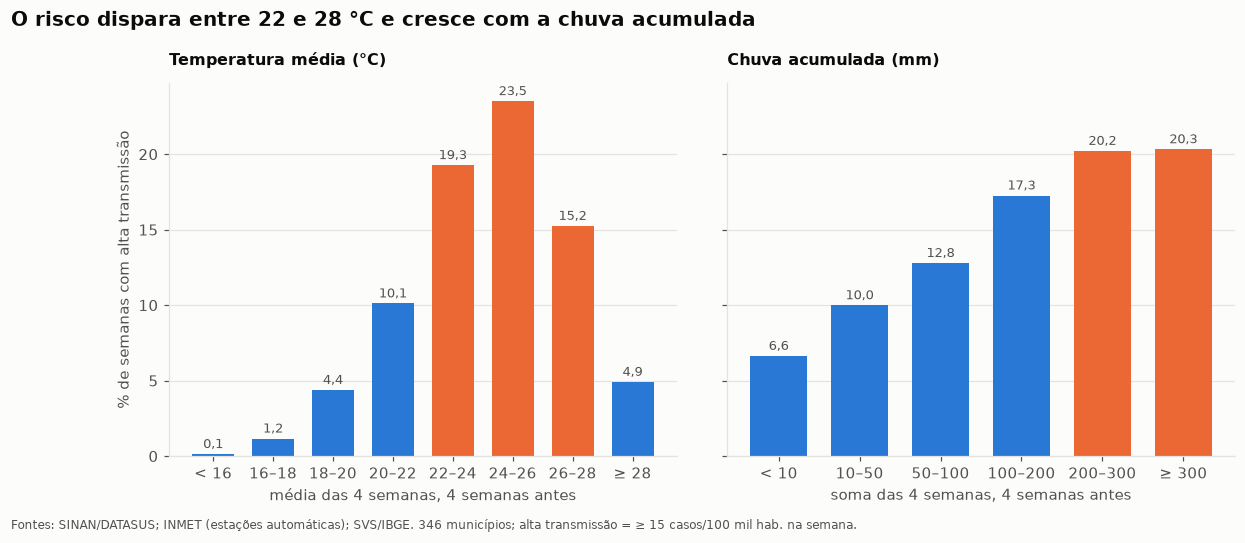

,faixa,semanas,pct_semanas_alta_transmissao,incidencia_media,incidencia_mediana,ordem,variavel
0,< 16,13734,0.13,0.190000,0.00,1,Temperatura
1,16–18,11549,1.16,0.970000,0.00,2,Temperatura
2,18–20,17578,4.38,2.940000,0.00,3,Temperatura
3,20–22,28151,10.11,8.600000,0.00,4,Temperatura
4,22–24,36921,19.27,22.320000,0.64,5,Temperatura
5,24–26,43056,23.51,27.469999,1.53,6,Temperatura
6,26–28,34094,15.25,14.900000,0.77,7,Temperatura
7,≥ 28,9671,4.91,3.670000,0.00,8,Temperatura
0,< 10,33256,6.63,4.640000,0.00,1,Chuva
1,10–50,36465,9.99,8.150000,0.00,2,Chuva


In [19]:
r = pdc[pdc["cod_municipio"].isin(AMOSTRA) & ~pdc["atraso_notificacao"]].sort_values(["cod_municipio", "id_semana"]).copy()
gr = r.groupby("cod_municipio", sort=False)
r["temp_4s"] = gr["temp_media_c"].transform(lambda s: s.rolling(JANELA, min_periods=3).mean())
r["chuva_4s"] = gr["precipitacao_mm"].transform(lambda s: s.rolling(JANELA, min_periods=3).sum())
r["temp_4s_lag"] = r.groupby("cod_municipio", sort=False)["temp_4s"].shift(DEFASAGEM)
r["chuva_4s_lag"] = r.groupby("cod_municipio", sort=False)["chuva_4s"].shift(DEFASAGEM)
r["alta"] = (r["incidencia_100k"] >= LIMIAR_ALTA).astype(int)

FX_T = [-np.inf, 16, 18, 20, 22, 24, 26, 28, np.inf]
ROT_T = ["< 16", "16–18", "18–20", "20–22", "22–24", "24–26", "26–28", "≥ 28"]
FX_C = [-np.inf, 10, 50, 100, 200, 300, np.inf]
ROT_C = ["< 10", "10–50", "50–100", "100–200", "200–300", "≥ 300"]
r["faixa_temp"] = pd.cut(r["temp_4s_lag"], FX_T, labels=ROT_T, right=False)
r["faixa_chuva"] = pd.cut(r["chuva_4s_lag"], FX_C, labels=ROT_C, right=False)


def risco_por_faixa(col: str) -> pd.DataFrame:
    t = r.dropna(subset=[col]).groupby(col, observed=True).agg(
        semanas=("alta", "size"), pct_semanas_alta_transmissao=("alta", "mean"),
        incidencia_media=("incidencia_100k", "mean"), incidencia_mediana=("incidencia_100k", "median")).reset_index()
    t["pct_semanas_alta_transmissao"] *= 100
    t["ordem"] = range(1, len(t) + 1)
    return t.rename(columns={col: "faixa"})


risco_t, risco_c = risco_por_faixa("faixa_temp"), risco_por_faixa("faixa_chuva")
OTIMA = ["22–24", "24–26", "26–28"]

fig, axs = plt.subplots(1, 2, figsize=(12.5, 4.4), sharey=True, gridspec_kw={"wspace": 0.1})
for ax, t, tit, xl, destaque in [
        (axs[0], risco_t, "Temperatura média (°C)", "média das 4 semanas, 4 semanas antes", OTIMA),
        (axs[1], risco_c, "Chuva acumulada (mm)", "soma das 4 semanas, 4 semanas antes", ["200–300", "≥ 300"])]:
    cores = [viz.LARANJA if f in destaque else viz.AZUL for f in t["faixa"]]
    ax.bar(t["faixa"].astype(str), t["pct_semanas_alta_transmissao"], color=cores, width=0.7)
    for x, v in enumerate(t["pct_semanas_alta_transmissao"]):
        ax.text(x, v + 0.4, viz.fmt_br(v, 1), ha="center", fontsize=8.5, color=viz.TEXTO_2)
    ax.set_title(tit, fontsize=10.5)
    ax.set_xlabel(xl)
axs[0].set_ylabel("% de semanas com alta transmissão")
fig.suptitle("O risco dispara entre 22 e 28 °C e cresce com a chuva acumulada", x=0.01, ha="left",
             fontsize=13, fontweight="bold", y=1.03)
viz.fonte(fig, FONTE_CLIMA + f" {len(AMOSTRA)} municípios; alta transmissão = ≥ 15 casos/100 mil hab. na semana.")
viz.salvar(fig, "08_risco_temperatura_chuva", FIGURAS)
plt.show()
pd.concat([risco_t.assign(variavel="Temperatura"), risco_c.assign(variavel="Chuva")]).round(2)

In [20]:
grupos_t = [g["incidencia_100k"].to_numpy() for _, g in r.dropna(subset=["faixa_temp"]).groupby("faixa_temp", observed=True)]
kw_t = stats.kruskal(*grupos_t)
dentro = r["faixa_temp"].isin(OTIMA)
mw_t = stats.mannwhitneyu(r.loc[dentro, "incidencia_100k"], r.loc[~dentro & r["faixa_temp"].notna(), "incidencia_100k"], alternative="greater")
risco_dentro = r.loc[dentro, "alta"].mean() * 100
risco_fora = r.loc[~dentro & r["faixa_temp"].notna(), "alta"].mean() * 100
registrar("H3", "Existe uma faixa ótima de temperatura para a transmissão (22–28 °C)",
          "Kruskal-Wallis entre faixas + Mann-Whitney (ótima > demais)",
          f"H = {viz.fmt_br(kw_t.statistic)}", p_fmt(mw_t.pvalue),
          f"risco {viz.fmt_br(risco_dentro, 1)}% (22–28 °C) vs {viz.fmt_br(risco_fora, 1)}% (demais): {viz.fmt_br(risco_dentro / risco_fora, 1)}x",
          "Confirmada", "Abaixo de 20 °C a transmissão quase some; acima de 28 °C o risco volta a cair.")

grupos_c = [g["incidencia_100k"].to_numpy() for _, g in r.dropna(subset=["faixa_chuva"]).groupby("faixa_chuva", observed=True)]
kw_c = stats.kruskal(*grupos_c)
rho_c = stats.spearmanr(risco_c["ordem"], risco_c["pct_semanas_alta_transmissao"])
seca = risco_c.set_index("faixa").loc["< 10", "pct_semanas_alta_transmissao"]
chuvosa = risco_c.set_index("faixa").loc["200–300", "pct_semanas_alta_transmissao"]
registrar("H4", "Mais chuva acumulada aumenta o risco — até um limite", "Kruskal-Wallis entre faixas de chuva",
          f"H = {viz.fmt_br(kw_c.statistic)}", p_fmt(kw_c.pvalue),
          f"risco {viz.fmt_br(chuvosa, 1)}% (200–300 mm) vs {viz.fmt_br(seca, 1)}% (< 10 mm)",
          "Confirmada" if risco_c["pct_semanas_alta_transmissao"].iloc[-1] <= chuvosa * 1.05 else "Parcial",
          "O risco cresce com a chuva acumulada até ~200 mm em 4 semanas e depois se estabiliza (platô): "
          "chuva cria criadouros, mas a partir de certo volume mais chuva não aumenta o risco.")
print(f"H3: Kruskal H={kw_t.statistic:,.0f} p {p_fmt(kw_t.pvalue)} | risco dentro {risco_dentro:.1f}% vs fora {risco_fora:.1f}%")
print(f"H4: Kruskal H={kw_c.statistic:,.0f} p {p_fmt(kw_c.pvalue)}")

H3: Kruskal H=19,864 p < 0,001 | risco dentro 19.7% vs fora 5.3%
H4: Kruskal H=2,252 p < 0,001


### 6.4 H5 — Anos mais quentes que o normal são mais epidêmicos?
Para cada município e ano comparamos o **início do ano (SE 1–20)** com a média do próprio município:
anomalia de temperatura (°C) × anomalia de incidência (log). Assim cada município é comparado consigo
mesmo, eliminando diferenças estruturais entre cidades.

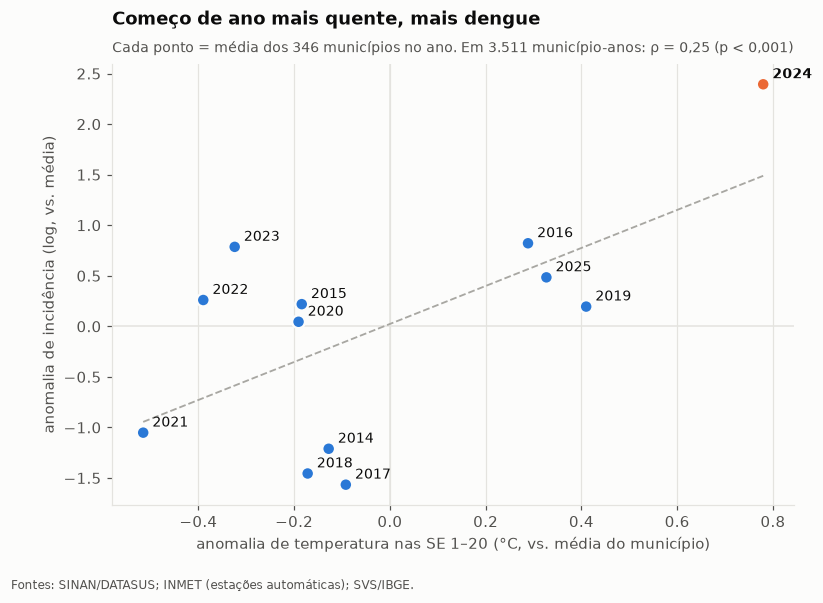

Município-ano: ρ = 0.251, p < 0,001 | entre anos: ρ = 0.27, p = 0.404


In [21]:
q = pdc[pdc["cod_municipio"].isin(AMOSTRA) & pdc["semana_epi"].between(1, 20) & (pdc["ano_epi"] <= ULTIMO_ANO_COMPLETO)]
ma = q.groupby(["cod_municipio", "ano_epi"]).agg(temp=("temp_media_c", "mean"), casos=("casos", "sum"), pop=("populacao", "first"))
ma = ma[q.groupby(["cod_municipio", "ano_epi"])["temp_media_c"].count() >= 14].copy()
ma["log_inc"] = np.log1p(ma["casos"] / ma["pop"] * 1e5)
ma["temp_anom"] = ma["temp"] - ma.groupby(level=0)["temp"].transform("mean")
ma["inc_anom"] = ma["log_inc"] - ma.groupby(level=0)["log_inc"].transform("mean")
ma = ma.dropna()
rho5, p5 = stats.spearmanr(ma["temp_anom"], ma["inc_anom"])
por_ano = ma.groupby(level=1)[["temp_anom", "inc_anom"]].mean()
rho5a, p5a = stats.spearmanr(por_ano["temp_anom"], por_ano["inc_anom"])

fig, ax = plt.subplots(figsize=(8, 5.2))
ax.axhline(0, color=viz.GRADE, lw=1)
ax.axvline(0, color=viz.GRADE, lw=1)
coef = np.polyfit(por_ano["temp_anom"], por_ano["inc_anom"], 1)
xx = np.linspace(por_ano["temp_anom"].min(), por_ano["temp_anom"].max(), 10)
ax.plot(xx, np.polyval(coef, xx), color=viz.NEUTRO, lw=1.2, ls="--")
cores = [viz.LARANJA if a == ano_rec else viz.AZUL for a in por_ano.index]
ax.scatter(por_ano["temp_anom"], por_ano["inc_anom"], s=70, color=cores, edgecolor=viz.SUPERFICIE, linewidth=1.5, zorder=3)
for a, (x, y) in por_ano.iterrows():
    ax.annotate(str(a), (x, y), xytext=(6, 4), textcoords="offset points", fontsize=9,
                fontweight="bold" if a == ano_rec else "normal")
ax.set_xlabel("anomalia de temperatura nas SE 1–20 (°C, vs. média do município)")
ax.set_ylabel("anomalia de incidência (log, vs. média)")
ax.grid(axis="both")
ax.set_title("Começo de ano mais quente, mais dengue")
viz.subtitulo(ax, f"Cada ponto = média dos {len(AMOSTRA)} municípios no ano. Em {viz.fmt_br(len(ma))} município-anos: "
                     f"ρ = {viz.fmt_br(rho5, 2)} (p {p_fmt(p5)})")
viz.fonte(fig, FONTE_CLIMA)
viz.salvar(fig, "09_anomalia_calor_anos_epidemicos", FIGURAS)
plt.show()

registrar("H5", "Anos com início mais quente que o normal são mais epidêmicos", "Spearman em anomalias município-ano (SE 1–20)",
          f"ρ = {viz.fmt_br(rho5, 3)} (n = {len(ma)} município-anos); entre anos ρ = {viz.fmt_br(rho5a, 2)}", p_fmt(p5),
          f"{ano_rec}: +{viz.fmt_br(por_ano.loc[ano_rec, 'temp_anom'], 2)} °C e maior anomalia de incidência da série",
          "Confirmada", "Calor acima do normal no verão/outono acompanha anos epidêmicos; não é a única causa (ver H7).")
print(f"Município-ano: ρ = {rho5:.3f}, p {p_fmt(p5)} | entre anos: ρ = {rho5a:.2f}, p = {p5a:.3f}")

## 7. H7 — Sorotipo: o fator que o clima não explica
Só ~2% dos casos têm sorotipo identificado (exame laboratorial), então os números absolutos são baixos —
mas a **composição** mostra a troca do vírus predominante.

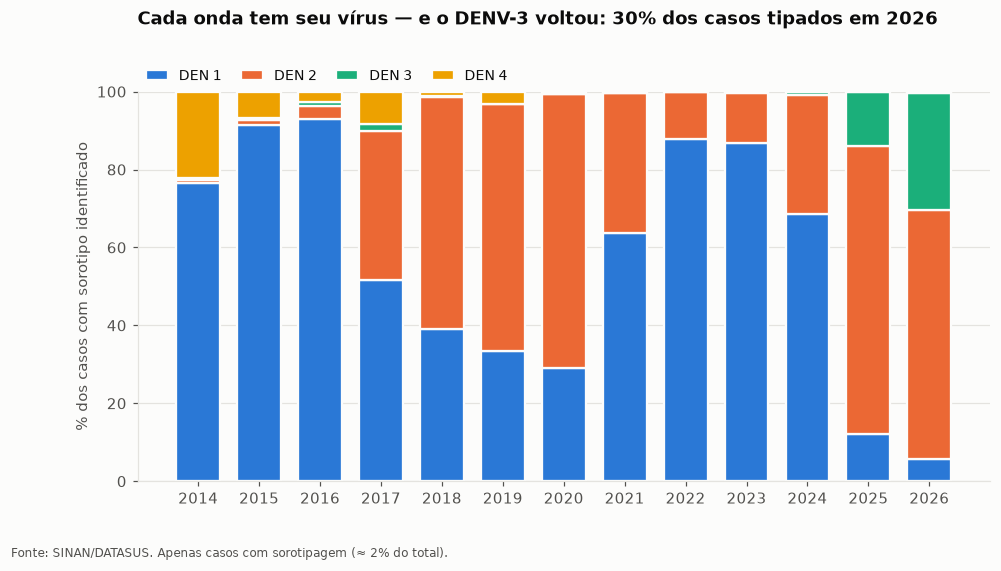

In [22]:
st = perfil[(perfil.dimensao == "Sorotipo") & (perfil.categoria != "Ignorado/Branco")].pivot_table(index="ano", columns="categoria", values="casos")
st_pct = st.div(st.sum(axis=1), axis=0) * 100
fig, ax = plt.subplots(figsize=(10, 4.6))
esq = np.zeros(len(st_pct))
for i, s in enumerate(["DEN 1", "DEN 2", "DEN 3", "DEN 4"]):
    ax.bar(st_pct.index, st_pct[s], bottom=esq, color=viz.CATEGORICA[i], width=0.72, label=s,
           edgecolor=viz.SUPERFICIE, linewidth=1.5)
    esq += st_pct[s].to_numpy()
ax.set_xticks(st_pct.index)
ax.set_ylim(0, 100)
ax.set_ylabel("% dos casos com sorotipo identificado")
den3_hist = st_pct.loc[:ANO_FIM - 2, "DEN 3"].max()
ax.set_title(f"Cada onda tem seu vírus — e o DENV-3 voltou: {viz.fmt_br(st_pct.loc[ANO_FIM, 'DEN 3'], 0)}% dos casos tipados em {ANO_FIM}", pad=44)
viz.legenda_topo(ax)
viz.fonte(fig, "Fonte: SINAN/DATASUS. Apenas casos com sorotipagem (≈ 2% do total).")
viz.salvar(fig, "10_sorotipos", FIGURAS)
plt.show()
chi2_s, p_s, _, _ = stats.chi2_contingency(st.fillna(0))
dom = st_pct.idxmax(axis=1)
registrar("H7", "A troca do sorotipo predominante acompanha anos epidêmicos (fator não climático)",
          "Descritiva + qui-quadrado (sorotipo × ano)", f"χ² = {viz.fmt_br(chi2_s)}", p_fmt(p_s),
          "Predominante por ano: " + ", ".join(f"{a}: {s}" for a, s in dom.items() if a in (2019, 2023, 2024, 2025)),
          "Parcial", f"O sorotipo predominante alterna (DENV-1 ↔ DENV-2). O DENV-3, que ficou ≤ {viz.fmt_br(den3_hist, 0)}% "
          f"dos casos tipados até {ANO_FIM - 2}, chegou a {viz.fmt_br(st_pct.loc[ANO_FIM, 'DEN 3'], 0)}% em {ANO_FIM}: "
          "risco para uma população sem imunidade a ele, que o clima não revela.")

## 8. H8 — Desigualdade: municípios em extrema pobreza

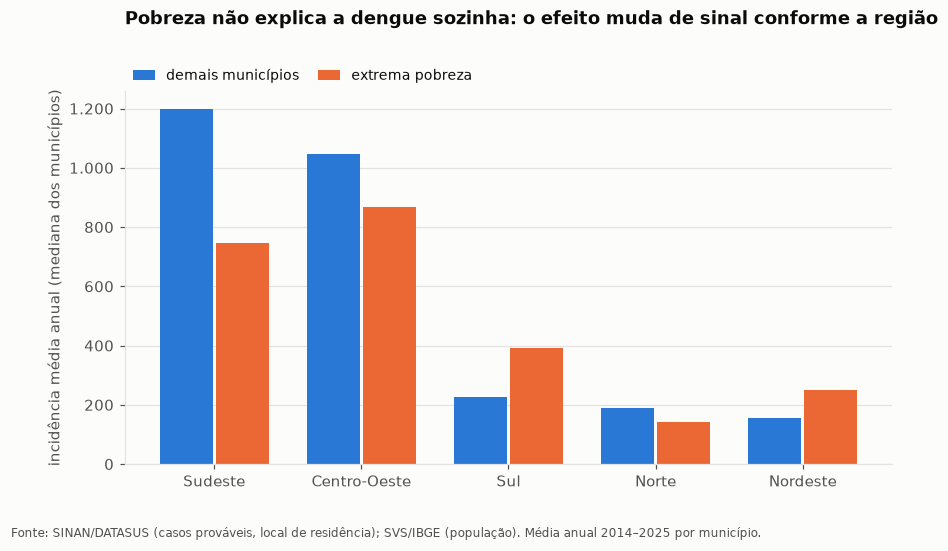

extrema_pobreza,Não,Sim
regiao,,
Centro-Oeste,1046.0,868.0
Nordeste,157.0,248.0
Norte,190.0,144.0
Sudeste,1198.0,746.0
Sul,227.0,391.0


In [23]:
inc_mun = anual[anual["ano"] <= ULTIMO_ANO_COMPLETO].groupby("cod_municipio")["incidencia_100k"].mean().rename("inc_media")
dm = dim_mun.set_index("cod_municipio")[["regiao", "extrema_pobreza"]].join(inc_mun)
mw8 = stats.mannwhitneyu(dm.loc[dm.extrema_pobreza == "Sim", "inc_media"], dm.loc[dm.extrema_pobreza == "Não", "inc_media"])
reg = dm.groupby(["regiao", "extrema_pobreza"])["inc_media"].median().unstack()
ordem_reg = reg["Não"].sort_values(ascending=False).index
fig, ax = plt.subplots(figsize=(9, 4.4))
x = np.arange(len(ordem_reg))
for i, (cat, rot) in enumerate([("Não", "demais municípios"), ("Sim", "extrema pobreza")]):
    ax.bar(x + (i - 0.5) * 0.38, reg.loc[ordem_reg, cat], width=0.36, color=viz.CATEGORICA[i], label=rot)
ax.set_xticks(x, ordem_reg)
ax.set_ylabel("incidência média anual (mediana dos municípios)")
viz.milhar(ax)
ax.set_title("Pobreza não explica a dengue sozinha: o efeito muda de sinal conforme a região", pad=44)
viz.legenda_topo(ax)
viz.fonte(fig, FONTE_SINAN + f" Média anual 2014–{ULTIMO_ANO_COMPLETO} por município.")
viz.salvar(fig, "11_desigualdade_regiao", FIGURAS)
plt.show()
med = dm.groupby("extrema_pobreza")["inc_media"].median()
registrar("H8", "Municípios em extrema pobreza têm incidência diferente", "Mann-Whitney (geral) + comparação por região",
          f"U = {viz.fmt_br(mw8.statistic)}", p_fmt(mw8.pvalue),
          f"mediana {viz.fmt_br(med['Sim'])} vs {viz.fmt_br(med['Não'])} casos/100 mil (pobreza vs demais)",
          "Parcial", "No agregado a pobreza tem MENOS casos, mas no Nordeste e no Sul tem MAIS: a região confunde; possível subnotificação.")
reg.round(0)

## 9. H9 — Modelo de alerta precoce

**Pergunta operacional:** *daqui a N semanas, este município estará em alta transmissão (≥ 15/100 mil)?*

* **Validação temporal:** treino 2014–2022, teste 2023–2026 (o modelo nunca "vê" o futuro).
* **Regressão logística** (interpretável, coeficientes explicáveis ao gestor público).
* Quatro conjuntos de variáveis, para isolar o valor do clima:
  1. **Sazonal** — só a semana do ano;
  2. **Sazonal + clima** — temperatura, faixa ótima, chuva, umidade e anomalia de temperatura (4 semanas);
  3. **Sazonal + vigilância** — incidência atual e da semana anterior;
  4. **Completo** — tudo.
* Métricas: **AUC** (capacidade de ordenar risco) e **AP** — *average precision*, mais informativa
  quando o evento é raro. Avaliamos também o subconjunto **"início de epidemia"** (incidência atual
  < 5/100 mil), que é quando o alerta realmente importa.

In [24]:
CONJ = {
    "Sazonal": ["sin", "cos"],
    "Sazonal + clima": ["sin", "cos", "temp_4s", "temp_otima", "chuva_log", "umid_4s", "temp_anom"],
    "Sazonal + vigilância": ["sin", "cos", "log_inc", "log_inc_l1"],
    "Completo": ["sin", "cos", "log_inc", "log_inc_l1", "temp_4s", "temp_otima", "chuva_log", "umid_4s", "temp_anom"],
}
TODAS = sorted(set(sum(CONJ.values(), [])))


def preparar(df: pd.DataFrame, h: int) -> pd.DataFrame:
    q = df.sort_values(["cod_municipio", "id_semana"]).copy()
    g = q.groupby("cod_municipio", sort=False)
    q["log_inc"] = np.log1p(q["incidencia_100k"])
    q["log_inc_l1"] = g["log_inc"].shift(1)
    q["temp_4s"] = g["temp_media_c"].transform(lambda s: s.rolling(JANELA, min_periods=3).mean())
    q["chuva_4s"] = g["precipitacao_mm"].transform(lambda s: s.rolling(JANELA, min_periods=3).sum())
    q["umid_4s"] = g["umidade_media_pct"].transform(lambda s: s.rolling(JANELA, min_periods=3).mean())
    q["temp_otima"] = q["temp_4s"].between(22, 28).astype(float).where(q["temp_4s"].notna())
    q["chuva_log"] = np.log1p(q["chuva_4s"])
    clim = q[q["ano_epi"] <= ANO_CORTE_TREINO].groupby(["cod_municipio", "semana_epi"])["temp_4s"].mean().rename("clim")
    q = q.join(clim, on=["cod_municipio", "semana_epi"])
    q["temp_anom"] = q["temp_4s"] - q["clim"]
    semana_alvo = (q["semana_epi"] + h - 1) % 52 + 1
    q["sin"], q["cos"] = np.sin(2 * np.pi * semana_alvo / 52), np.cos(2 * np.pi * semana_alvo / 52)
    q["id_semana_alvo"] = g["id_semana"].shift(-h)
    q["inc_alvo"] = g["incidencia_100k"].shift(-h)
    alvo_valido = q["inc_alvo"].notna() & ~g["atraso_notificacao"].shift(-h).fillna(True).astype(bool)
    q["alvo"] = (q["inc_alvo"] >= LIMIAR_ALTA).astype(float).where(alvo_valido)
    q["conjunto"] = np.where(q["ano_epi"] <= ANO_CORTE_TREINO, "treino", "teste")
    return q


def ajustar(tr: pd.DataFrame, cols: list[str]):
    return make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000)).fit(tr[cols], tr["alvo"])


avaliacao = []
for h in (4, 8, 12):
    q = preparar(pdc[pdc["cod_municipio"].isin(AMOSTRA_50K)], h).dropna(subset=TODAS + ["alvo"])
    tr, te = q[q.conjunto == "treino"], q[q.conjunto == "teste"]
    for nome, cols in CONJ.items():
        prob = ajustar(tr, cols).predict_proba(te[cols])[:, 1]
        for sub, m in [("Todas as semanas", np.ones(len(te), bool)), ("Início de epidemia (<5/100 mil)", (te["incidencia_100k"] < 5).to_numpy())]:
            y = te["alvo"].to_numpy()[m]
            avaliacao.append(dict(horizonte_semanas=h, subconjunto=sub, modelo=nome, n_semanas=int(m.sum()),
                                  prevalencia_pct=y.mean() * 100, auc=roc_auc_score(y, prob[m]),
                                  ap=average_precision_score(y, prob[m]), brier=brier_score_loss(y, prob[m])))
aval = pd.DataFrame(avaliacao)
aval.pivot_table(index=["subconjunto", "modelo"], columns="horizonte_semanas", values=["auc", "ap"]).round(3)

ap                \
horizonte_semanas                                        4      8      12   
subconjunto                     modelo                                      
Início de epidemia (<5/100 mil) Completo              0.145  0.304  0.372   
                                Sazonal               0.033  0.116  0.202   
                                Sazonal + clima       0.037  0.143  0.301   
                                Sazonal + vigilância  0.143  0.260  0.302   
Todas as semanas                Completo              0.909  0.808  0.699   
                                Sazonal               0.378  0.378  0.375   
                                Sazonal + clima       0.420  0.444  0.477   
                                Sazonal + vigilância  0.906  0.800  0.688   

                                                        auc                
horizonte_semanas                                        4      8      12  
subconjunto                     modelo                                     
Início de epidemia (<5/100 mil) Completo              0.879  0.884  0.866  
                                Sazonal               0.700  0.758  0.779  
                                Sazonal + clima       0.733  0.801  0.819  
                                Sazonal + vigilância  0.875  0.870  0.848  
Todas as semanas                Completo              0.967  0.929  0.889  
                                Sazonal               0.748  0.748  0.749  
                                Sazonal + clima       0.772  0.788  0.790  
                                Sazonal + vigilância  0.967  0.926  0.884

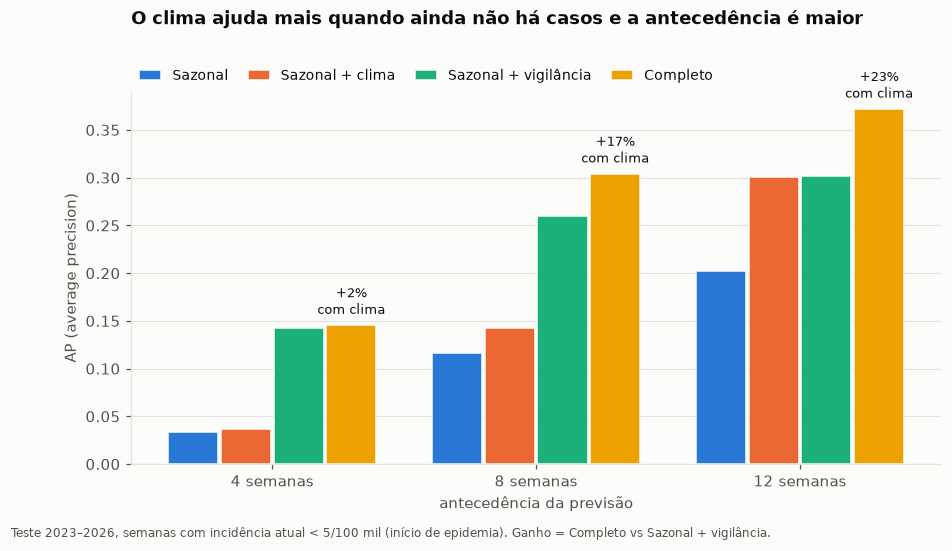

In [25]:
ini = aval[aval.subconjunto.str.startswith("Início")].pivot_table(index="horizonte_semanas", columns="modelo", values="ap")
fig, ax = plt.subplots(figsize=(9.5, 4.4))
x = np.arange(len(ini))
mods = ["Sazonal", "Sazonal + clima", "Sazonal + vigilância", "Completo"]
for i, mname in enumerate(mods):
    ax.bar(x + (i - 1.5) * 0.2, ini[mname], width=0.19, color=viz.CATEGORICA[i], label=mname,
           edgecolor=viz.SUPERFICIE, linewidth=1)
ganho = (ini["Completo"] / ini["Sazonal + vigilância"] - 1) * 100
for xi, (h, gnh) in enumerate(ganho.items()):
    ax.text(xi + 0.3, ini.loc[h, "Completo"] + 0.012, f"+{viz.fmt_br(gnh, 0)}%\ncom clima", ha="center", fontsize=8.5)
ax.set_xticks(x, [f"{h} semanas" for h in ini.index])
ax.set_xlabel("antecedência da previsão")
ax.set_ylabel("AP (average precision)")
ax.set_title("O clima ajuda mais quando ainda não há casos e a antecedência é maior", pad=44)
viz.legenda_topo(ax)
viz.fonte(fig, "Teste 2023–2026, semanas com incidência atual < 5/100 mil (início de epidemia). "
               "Ganho = Completo vs Sazonal + vigilância.")
viz.salvar(fig, "12_modelo_valor_do_clima", FIGURAS)
plt.show()

**Leitura:** com antecedência curta (4 semanas), quem manda é a **vigilância** — se já há casos, eles
continuam. À medida que a antecedência cresce e o município ainda está "calmo", o **clima** passa a
acrescentar informação que os casos ainda não mostram. É exatamente o cenário de prevenção.

### 9.1 Modelo final do alerta (horizonte de 8 semanas) e incerteza do ganho
Intervalo de confiança do ganho de AP por **bootstrap por município** (reamostra cidades inteiras, para
respeitar a dependência temporal dentro de cada série).

In [26]:
qf = preparar(pdc, HORIZONTE)
amostra_mod = qf["cod_municipio"].isin(AMOSTRA_50K)
dados = qf[amostra_mod].dropna(subset=TODAS + ["alvo"])
tr, te = dados[dados.conjunto == "treino"], dados[dados.conjunto == "teste"]
mod_final = ajustar(tr, CONJ["Completo"])
mod_vig = ajustar(tr, CONJ["Sazonal + vigilância"])
te = te.assign(p_final=mod_final.predict_proba(te[CONJ["Completo"]])[:, 1],
               p_vig=mod_vig.predict_proba(te[CONJ["Sazonal + vigilância"]])[:, 1])
ini_te = te[te["incidencia_100k"] < 5]
rng = np.random.default_rng(42)
cods = ini_te["cod_municipio"].unique()
por_mun = {c: d for c, d in ini_te.groupby("cod_municipio")}
deltas = []
for _ in range(300):
    b = pd.concat([por_mun[c] for c in rng.choice(cods, len(cods))])
    if b["alvo"].nunique() == 2:
        deltas.append(average_precision_score(b["alvo"], b["p_final"]) - average_precision_score(b["alvo"], b["p_vig"]))
ic = np.percentile(deltas, [2.5, 97.5])
d_ap = average_precision_score(ini_te["alvo"], ini_te["p_final"]) - average_precision_score(ini_te["alvo"], ini_te["p_vig"])
coefs = pd.Series(mod_final[-1].coef_[0], index=CONJ["Completo"]).sort_values()
registrar("H9", "Incluir o clima melhora a previsão de semanas de alta transmissão",
          f"Regressão logística, treino 2014–{ANO_CORTE_TREINO}, teste {ANO_CORTE_TREINO + 1}–{ANO_FIM}, horizonte {HORIZONTE} semanas",
          f"AUC completo = {viz.fmt_br(roc_auc_score(te['alvo'], te['p_final']), 3)}; "
          f"ΔAP início de epidemia = {viz.fmt_br(d_ap, 3)} (IC95% {viz.fmt_br(ic[0], 3)} a {viz.fmt_br(ic[1], 3)})",
          "bootstrap", f"ganho relativo de AP no início de epidemia: {viz.fmt_br(ganho.loc[HORIZONTE], 0)}%",
          "Confirmada" if ic[0] > 0 else "Parcial",
          "O clima acrescenta antecedência ao alerta; a vigilância de casos continua sendo a base.")
print(f"ΔAP (início de epidemia, {HORIZONTE} semanas) = {d_ap:.3f}  IC95% [{ic[0]:.3f}; {ic[1]:.3f}]")
print("Coeficientes padronizados do modelo final:")
print(coefs.round(2).to_string())

ΔAP (início de epidemia, 8 semanas) = 0.044  IC95% [0.018; 0.067]
Coeficientes padronizados do modelo final:
umid_4s      -0.29
temp_4s      -0.04
temp_anom     0.12
log_inc_l1    0.31
temp_otima    0.34
chuva_log     0.44
cos           0.67
sin           1.08
log_inc       1.58


### 9.2 Níveis de alerta
A probabilidade vira um **nível de alerta** com quatro faixas. A tabela mostra, no período de teste,
com que frequência cada nível foi seguido de fato por alta transmissão 8 semanas depois — é o que
dá confiança ao gestor para agir.

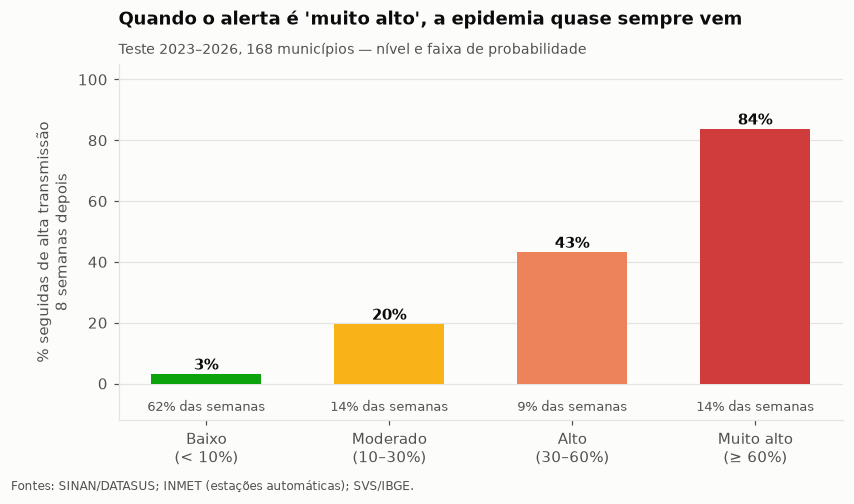

,nivel_alerta,semanas,pct_alta_transmissao_observada,pct_semanas,ordem,faixa_probabilidade
0,Baixo,14855,3.089869,62.436954,1,< 10%
1,Moderado,3439,19.511486,14.454438,2,10–30%
2,Alto,2223,43.139901,9.343477,3,30–60%
3,Muito alto,3275,83.694656,13.765131,4,≥ 60%


In [27]:
NIVEIS = ["Baixo", "Moderado", "Alto", "Muito alto"]
CORTES = [0, 0.10, 0.30, 0.60, 1.0001]
te["nivel_alerta"] = pd.cut(te["p_final"], CORTES, labels=NIVEIS, right=False)
niv = te.groupby("nivel_alerta", observed=True).agg(semanas=("alvo", "size"), pct_alta_transmissao_observada=("alvo", "mean")).reset_index()
niv["pct_alta_transmissao_observada"] *= 100
niv["pct_semanas"] = niv["semanas"] / niv["semanas"].sum() * 100
niv["ordem"] = range(1, len(niv) + 1)
niv["faixa_probabilidade"] = ["< 10%", "10–30%", "30–60%", "≥ 60%"][: len(niv)]

fig, ax = plt.subplots(figsize=(8.5, 4.2))
cores = [viz.STATUS[n.lower()] for n in niv["nivel_alerta"]]
ax.bar(niv["nivel_alerta"].astype(str), niv["pct_alta_transmissao_observada"], color=cores, width=0.6)
for x_, (v, s) in enumerate(zip(niv["pct_alta_transmissao_observada"], niv["pct_semanas"])):
    ax.text(x_, v + 1.5, f"{viz.fmt_br(v, 0)}%", ha="center", fontsize=10, fontweight="bold")
    ax.text(x_, -9, f"{viz.fmt_br(s, 0)}% das semanas", ha="center", fontsize=8.5, color=viz.TEXTO_2)
ax.set_ylim(-12, 105)
ax.set_xticks(range(len(niv)), [f"{n}\n({f})" for n, f in zip(niv["nivel_alerta"], niv["faixa_probabilidade"])])
ax.set_ylabel(f"% seguidas de alta transmissão\n{HORIZONTE} semanas depois")
ax.set_title("Quando o alerta é 'muito alto', a epidemia quase sempre vem")
viz.subtitulo(ax, f"Teste {ANO_CORTE_TREINO + 1}–{ANO_FIM}, {len(AMOSTRA_50K)} municípios — nível e faixa de probabilidade")
viz.fonte(fig, FONTE_CLIMA)
viz.salvar(fig, "13_niveis_alerta", FIGURAS)
plt.show()
niv

### 9.3 O alerta na prática — exemplo de uma capital
Painel de cima: incidência observada. Painel de baixo: probabilidade que o modelo calculou **8 semanas
antes** para aquela semana. O alerta sobe antes da curva de casos.

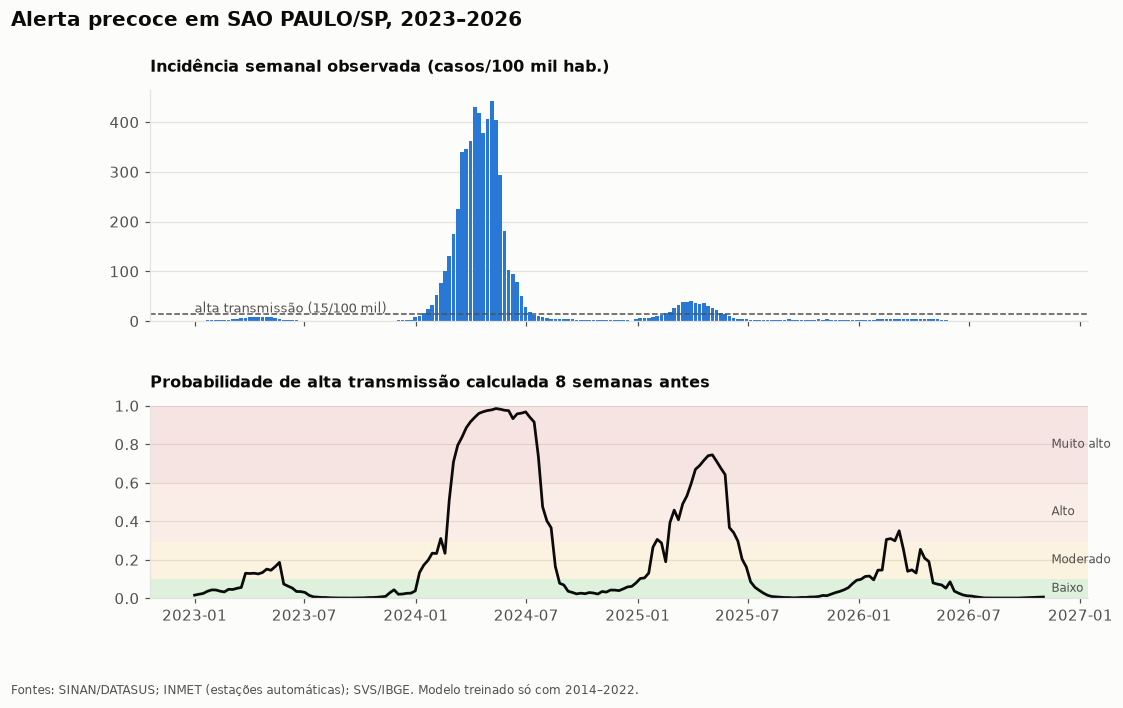

In [28]:
caps = dim_mun[(dim_mun.capital == "Sim") & dim_mun.cod_municipio.isin(AMOSTRA_50K)]["cod_municipio"]
qf["p_final"] = np.nan
okf = qf[CONJ["Completo"]].notna().all(axis=1)
qf.loc[okf, "p_final"] = mod_final.predict_proba(qf.loc[okf, CONJ["Completo"]])[:, 1]
ex_cod = (anual[anual.cod_municipio.isin(caps) & anual.ano.between(2023, 2025)].groupby("cod_municipio")["casos"].sum().idxmax())
ex_nome = dim_mun.set_index("cod_municipio").loc[ex_cod, "municipio_uf"]
ex = qf[qf.cod_municipio == ex_cod][["id_semana", "incidencia_100k", "p_final", "id_semana_alvo"]]
prev = ex[["id_semana_alvo", "p_final"]].dropna().rename(columns={"id_semana_alvo": "id_semana", "p_final": "p_prevista"})
prev["id_semana"] = prev["id_semana"].astype(int)
ex = ex.merge(prev, on="id_semana", how="left").merge(dim_tempo[["id_semana", "data_inicio"]])
ex = ex[ex["data_inicio"] >= "2023-01-01"]

fig, (a1, a2) = plt.subplots(2, 1, figsize=(11, 6), sharex=True, gridspec_kw={"hspace": 0.4, "height_ratios": [1.2, 1]})
a1.bar(ex["data_inicio"], ex["incidencia_100k"], width=6, color=viz.AZUL)
a1.axhline(LIMIAR_ALTA, color=viz.TEXTO_2, lw=1, ls="--")
a1.text(ex["data_inicio"].iloc[0], LIMIAR_ALTA * 1.15, "alta transmissão (15/100 mil)", fontsize=8.5, color=viz.TEXTO_2)
a1.set_title("Incidência semanal observada (casos/100 mil hab.)", fontsize=10.5)
for lo, hi, n in zip(CORTES[:-1], CORTES[1:], NIVEIS):
    a2.axhspan(lo, min(hi, 1), color=viz.STATUS[n.lower()], alpha=0.12, lw=0)
    a2.text(ex["data_inicio"].iloc[-1], (lo + min(hi, 1)) / 2, f"  {n}", fontsize=8, va="center", color=viz.TEXTO_2)
a2.plot(ex["data_inicio"], ex["p_prevista"], color=viz.TEXTO, lw=1.8)
a2.set_ylim(0, 1)
a2.set_title(f"Probabilidade de alta transmissão calculada {HORIZONTE} semanas antes", fontsize=10.5)
fig.suptitle(f"Alerta precoce em {ex_nome}, 2023–{ANO_FIM}", x=0.01, ha="left", fontsize=13, fontweight="bold", y=1.0)
viz.fonte(fig, FONTE_CLIMA + " Modelo treinado só com 2014–2022.")
viz.salvar(fig, "14_exemplo_alerta_capital", FIGURAS)
plt.show()

## 10. Fato dengue × clima (com alerta) e exportação das métricas

In [29]:
fdc = qf[["id_semana", "cod_municipio", "casos", "incidencia_100k", "temp_media_c", "precipitacao_mm", "umidade_media_pct",
          "temp_4s", "chuva_4s", "p_final", "id_semana_alvo", "inc_alvo", "conjunto"]].copy()
fdc["alta_transmissao"] = sim_nao(fdc["incidencia_100k"] >= LIMIAR_ALTA)
fdc["faixa_temperatura_4s"] = pd.cut(fdc["temp_4s"], FX_T, labels=ROT_T, right=False).astype("string").fillna("Sem dado")
fdc["faixa_chuva_4s"] = pd.cut(fdc["chuva_4s"], FX_C, labels=ROT_C, right=False).astype("string").fillna("Sem dado")
fdc["temperatura_faixa_otima"] = np.where(fdc["temp_4s"].isna(), "Sem dado", sim_nao(fdc["temp_4s"].between(22, 28)))
fdc["nivel_alerta"] = pd.cut(fdc["p_final"], CORTES, labels=NIVEIS, right=False).astype("string").fillna("Sem dado")
fdc["alta_transmissao_em_8s"] = np.where(fdc["inc_alvo"].isna(), "Sem dado", sim_nao(fdc["inc_alvo"] >= LIMIAR_ALTA))
fdc["municipio_amostra_modelo"] = sim_nao(fdc["cod_municipio"].isin(AMOSTRA_50K))
fdc = fdc.rename(columns={"temp_4s": "temp_media_4s_c", "chuva_4s": "chuva_4s_mm", "p_final": "prob_alta_transmissao_8s",
                          "id_semana_alvo": "id_semana_alvo", "conjunto": "periodo_modelo"}).drop(columns="inc_alvo")
fdc["id_semana_alvo"] = fdc["id_semana_alvo"].astype("Int64")
exportar(fdc, "fato_dengue_clima_semanal")

# Métricas
kpis_extra = [
    ("% dos casos nas SE 1–22", pct_1o, "%", "Concentração sazonal (H1)"),
    ("Semanas entre o pico da chuva e o pico dos casos", pico_casos - pico_chuva, "semanas", "Climatologia (H1)"),
    ("Risco de alta transmissão na faixa 22–28 °C", risco_dentro, "% das semanas", "H3"),
    ("Risco de alta transmissão fora da faixa 22–28 °C", risco_fora, "% das semanas", "H3"),
    ("Letalidade 80+ vs 20–39 anos", rr, "vezes", "H6"),
    (f"AUC do alerta ({HORIZONTE} semanas)", roc_auc_score(te["alvo"], te["p_final"]), "0–1", "Teste 2023–2026"),
    (f"Ganho de AP com clima no início de epidemia ({HORIZONTE} semanas)", ganho.loc[HORIZONTE], "%", "H9"),
    ("Municípios com estação do INMET", dim_mun.possui_estacao_inmet.eq("Sim").sum(), "municípios", "Integração"),
    ("População coberta por municípios com estação",
     dim_mun.loc[dim_mun.possui_estacao_inmet == "Sim", "populacao_2025"].sum() / dim_mun["populacao_2025"].sum() * 100, "%", "2025"),
]
kpi_df = pd.concat([kpi_df, pd.DataFrame(kpis_extra, columns=kpi_df.columns)], ignore_index=True)
kpi_df["valor"] = kpi_df["valor"].astype(float).round(3)
exportar(kpi_df, "metricas_kpis")
exportar(pd.DataFrame(hipoteses), "resultados_hipoteses")
exportar(defas.round(4), "metricas_defasagem_clima")
exportar(risco_t.assign(faixa=risco_t["faixa"].astype(str)).round(3), "metricas_risco_temperatura")
exportar(risco_c.assign(faixa=risco_c["faixa"].astype(str)).round(3), "metricas_risco_chuva")
exportar(aval.round(4), "metricas_modelo_alerta")
exportar(niv.assign(nivel_alerta=niv["nivel_alerta"].astype(str)).round(3), "metricas_niveis_alerta")
pd.DataFrame(hipoteses)[["id", "hipotese", "resultado", "p_valor", "tamanho_efeito"]]

,id,hipotese,resultado,p_valor,tamanho_efeito
0,H6,Idosos têm maior risco de morte por dengue,Confirmada,"< 0,001","V de Cramér = 0,066 | 80+ vs 20–39: 44,8x"
1,H1,Os casos se concentram no 1º semestre (SE 1–22),Confirmada,"< 0,001","84,7% dos casos em 42% das semanas"
2,H2,Chuva e calor antecedem os casos em algumas se...,Confirmada (com ressalva),"< 0,001",84% dos municípios com ρ > 0 significativo (te...
3,H3,Existe uma faixa ótima de temperatura para a t...,Confirmada,"< 0,001","risco 19,7% (22–28 °C) vs 5,3% (demais): 3,7x"
4,H4,Mais chuva acumulada aumenta o risco — até um ...,Confirmada,"< 0,001","risco 20,2% (200–300 mm) vs 6,6% (< 10 mm)"
5,H5,Anos com início mais quente que o normal são m...,Confirmada,"< 0,001","2024: +0,78 °C e maior anomalia de incidência ..."
6,H7,A troca do sorotipo predominante acompanha ano...,Parcial,"< 0,001","Predominante por ano: 2019: DEN 2, 2023: DEN 1..."
7,H8,Municípios em extrema pobreza têm incidência d...,Parcial,"< 0,001",mediana 298 vs 552 casos/100 mil (pobreza vs d...
8,H9,Incluir o clima melhora a previsão de semanas ...,Confirmada,bootstrap,ganho relativo de AP no início de epidemia: 17%


## 11. Dicionário de dados

In [30]:
DESC = {
    "id_semana": "Semana epidemiológica no formato AAAASS (chave da dim_tempo_semana)",
    "ano_epi": "Ano epidemiológico", "semana_epi": "Semana epidemiológica (1–53)",
    "data_inicio": "Domingo que inicia a semana", "data_fim": "Sábado que encerra a semana",
    "mes_referencia": "Mês do meio da semana (1–12)", "nome_mes": "Nome abreviado do mês", "trimestre": "Trimestre (1–4)",
    "estacao_ano": "Estação do ano (hemisfério sul)", "periodo_sazonal": "Alta (SE 1–22) ou baixa temporada da dengue",
    "rotulo_semana": "Rótulo AAAA/SEss", "dado_preliminar": "Sim = ano corrente, sujeito a revisão pela fonte",
    "atraso_notificacao": "Sim = uma das 4 últimas semanas publicadas (casos ainda sendo digitados)",
    "ano": "Ano epidemiológico", "ano_parcial": "Sim = ano ainda em curso", "rotulo_ano": "Rótulo do ano para exibição",
    "cod_uf": "Código IBGE da UF (2 dígitos)", "sigla_uf": "Sigla da UF", "nome_uf": "Nome da UF", "regiao": "Grande região",
    "cod_municipio": "Código IBGE do município (6 dígitos, padrão DATASUS)", "nome_municipio": "Nome do município (SINAN)",
    "municipio_uf": "Município/UF (use como categoria 'Cidade' no mapa do Power BI)",
    "capital": "Sim = capital estadual", "extrema_pobreza": "Sim = classificado como município em extrema pobreza (filtro do TabNet)",
    "porte": "Porte populacional (2025)", "populacao_2025": "População residente estimada em 2025",
    "possui_estacao_inmet": "Sim = há estação automática do INMET associada", "qtd_estacoes": "Nº de estações associadas",
    "amostra_clima": "Sim = estação com ≥ 70% das semanas com temperatura válida (usado nas análises clima × dengue)",
    "latitude": "Latitude (graus decimais; nos municípios, média das estações)", "longitude": "Longitude (graus decimais)",
    "codigo_wmo": "Código da estação INMET", "nome_estacao": "Nome da estação", "altitude": "Altitude da estação (m)",
    "data_fundacao": "Data de fundação da estação", "primeiro_ano": "Primeiro ano com dados", "ultimo_ano": "Último ano com dados",
    "semanas_validas_temp": "Semanas com temperatura válida", "semanas_validas_precip": "Semanas com chuva válida",
    "casos": "Casos prováveis de dengue (exclui descartados), por local de residência",
    "incidencia_100k": "Casos por 100 mil habitantes",
    "alta_transmissao": "Sim = incidência semanal ≥ 15 casos/100 mil hab.",
    "populacao": "População residente estimada no ano (2026 repete 2025)",
    "semanas_alta_transmissao": "Nº de semanas do ano com incidência ≥ 15/100 mil",
    "semana_pico": "Semana epidemiológica com mais casos no ano", "casos_semana_pico": "Casos na semana de pico",
    "nivel_incidencia": "Classificação anual do Ministério da Saúde (baixa < 100, média 100–299, alta ≥ 300)",
    "rank_incidencia_uf": "Posição do município na UF pela incidência do ano (1 = maior)",
    "precipitacao_mm": "Chuva acumulada na semana (mm)", "precipitacao_max_diaria_mm": "Maior chuva diária da semana (mm)",
    "dias_chuva": "Dias com chuva ≥ 1 mm", "temp_media_c": "Temperatura média da semana (°C)",
    "temp_max_media_c": "Média das máximas diárias (°C)", "temp_min_media_c": "Média das mínimas diárias (°C)",
    "umidade_media_pct": "Umidade relativa média (%)", "n_dias_validos_temp": "Dias com temperatura válida na semana",
    "n_dias_validos_precip": "Dias com chuva válida na semana",
    "dimensao": "Variável do perfil (faixa etária, sexo, raça/cor, classificação, evolução, hospitalização, sorotipo)",
    "categoria": "Categoria da dimensão", "ordem": "Ordem de exibição da categoria", "pct_no_ano": "% dos casos do ano na categoria",
    "faixa_etaria": "Faixa etária", "ordem_faixa": "Ordem da faixa etária", "curas": "Casos que evoluíram para cura",
    "obitos_dengue": "Óbitos pelo agravo (dengue)", "obitos_em_investigacao": "Óbitos ainda em investigação",
    "hospitalizados": "Casos hospitalizados", "hospitalizacao_informada": "Casos com o campo hospitalização preenchido",
    "letalidade_pct": "Óbitos por dengue / casos × 100", "obitos_por_100mil_casos": "Óbitos por dengue por 100 mil casos",
    "taxa_hospitalizacao_pct": "Hospitalizados / casos com o campo preenchido × 100", "pct_casos": "% do total de casos",
    "temp_media_4s_c": "Temperatura média das últimas 4 semanas (°C)", "chuva_4s_mm": "Chuva acumulada nas últimas 4 semanas (mm)",
    "faixa_temperatura_4s": "Faixa da temperatura média de 4 semanas", "faixa_chuva_4s": "Faixa da chuva acumulada de 4 semanas",
    "temperatura_faixa_otima": "Sim = temperatura de 4 semanas entre 22 e 28 °C (faixa de maior risco)",
    "prob_alta_transmissao_8s": "Probabilidade (0–1) de alta transmissão daqui a 8 semanas — modelo de alerta",
    "id_semana_alvo": "Semana a que a previsão se refere (id_semana + 8)",
    "periodo_modelo": "treino (≤ 2022) ou teste (≥ 2023)",
    "nivel_alerta": "Baixo (<10%), Moderado (10–30%), Alto (30–60%), Muito alto (≥60%)",
    "alta_transmissao_em_8s": "O que de fato aconteceu 8 semanas depois (Sim/Não/Sem dado)",
    "municipio_amostra_modelo": "Sim = município usado para treinar/avaliar o modelo (≥ 50 mil hab., cobertura ≥ 70%)",
    "indicador": "Nome do indicador", "valor": "Valor do indicador", "unidade": "Unidade", "descricao": "Recorte/observação",
    "id": "Identificador da hipótese", "hipotese": "Enunciado da hipótese", "metodo": "Técnica estatística",
    "estatistica": "Estatística do teste", "p_valor": "p-valor", "tamanho_efeito": "Magnitude do efeito",
    "resultado": "Confirmada / Parcial / Não confirmada", "interpretacao": "Leitura para o gestor/pitch",
    "variavel": "Variável climática", "defasagem_semanas": "Semanas entre o clima e os casos",
    "tipo": "bruta (com sazonalidade) ou anomalia (sem sazonalidade)", "rho_mediana": "Mediana do ρ de Spearman entre municípios",
    "rho_p25": "1º quartil do ρ", "rho_p75": "3º quartil do ρ",
    "pct_municipios_positivos_signif": "% dos municípios com ρ > 0 e p < 0,05", "municipios": "Nº de municípios",
    "faixa": "Faixa da variável climática", "semanas": "Nº de semanas", "pct_semanas_alta_transmissao": "% das semanas com alta transmissão",
    "incidencia_media": "Incidência semanal média", "incidencia_mediana": "Incidência semanal mediana",
    "horizonte_semanas": "Antecedência da previsão (semanas)", "subconjunto": "Recorte de avaliação", "modelo": "Conjunto de variáveis",
    "n_semanas": "Semanas avaliadas", "prevalencia_pct": "% de semanas de alta transmissão no recorte",
    "auc": "Área sob a curva ROC", "ap": "Average precision", "brier": "Brier score (erro quadrático da probabilidade)",
    "pct_alta_transmissao_observada": "% seguidas de alta transmissão 8 semanas depois", "pct_semanas": "% das semanas no nível",
    "faixa_probabilidade": "Faixa de probabilidade do nível",
}
linhas_dic = []
for nome, _, _ in exportados:
    cab = pd.read_csv(SAIDA / f"{nome}.csv", sep=";", nrows=0, encoding="utf-8-sig").columns
    for col in cab:
        linhas_dic.append((nome, col, DESC.get(col, "")))
dic = pd.DataFrame(linhas_dic, columns=["tabela", "coluna", "descricao"])
faltando = dic[dic.descricao == ""]
assert faltando.empty, faltando
exportar(dic, "dicionario_dados")
resumo = pd.DataFrame(exportados, columns=["arquivo", "linhas", "colunas"])
resumo["MB"] = [round((SAIDA / f"{n}.csv").stat().st_size / 1e6, 2) for n in resumo["arquivo"]]
resumo

,arquivo,linhas,colunas,MB
0,dim_tempo_semana,671,13,0.07
1,dim_ano,13,3,0.00
2,dim_uf,27,4,0.00
3,dim_municipio,5571,16,0.63
4,dim_estacao,705,13,0.06
5,fato_dengue_semanal,898923,5,25.50
6,fato_dengue_anual_municipio,72423,10,4.05
7,fato_clima_semanal_estacao,372465,11,19.05
8,fato_perfil_anual,507,6,0.02
9,fato_gravidade_faixa_etaria,11,12,0.00


## 12. Conclusões

In [31]:
m_def = melhor["defasagem_semanas"].astype(int)
niv_i = niv.set_index("nivel_alerta")["pct_alta_transmissao_observada"]
cob_pop = dim_mun.loc[dim_mun.possui_estacao_inmet == "Sim", "populacao_2025"].sum() / dim_mun["populacao_2025"].sum() * 100
display(Markdown(f"""
### Os 3 principais insights (para o pitch e o painel)

1. **A dengue tem calendário — e o clima marca o relógio.** {viz.fmt_br(pct_1o, 0)}% dos casos acontecem entre janeiro
   e maio (SE 1–22). A estação chuvosa (novembro–março) e o pico de calor (janeiro) vêm antes do pico de casos (abril,
   SE{pico_casos}). As correlações defasadas são máximas com ~{m_def['Umidade']} semanas para a umidade,
   ~{m_def['Chuva']} para a chuva e ~{m_def['Temperatura']} para a temperatura. Na **faixa de 22–28 °C** a chance de uma
   semana de alta transmissão é **{viz.fmt_br(risco_dentro / risco_fora, 1)} vezes maior** ({viz.fmt_br(risco_dentro, 1)}% contra
   {viz.fmt_br(risco_fora, 1)}%).
2. **Calor fora do normal acompanha anos epidêmicos — mas o clima não age sozinho.** Municípios e anos com início mais
   quente que o habitual têm mais dengue que o habitual (ρ = {viz.fmt_br(rho5, 2)} em {viz.fmt_br(len(ma))} município-anos).
   {ano_rec}, com início ~{viz.fmt_br(por_ano.loc[ano_rec, 'temp_anom'], 1)} °C acima da média, teve
   {viz.fmt_br(br_ano.loc[ano_rec, 'casos'] / 1e6, 2)} milhões de casos — o recorde. O vírus também muda: o DENV-3,
   quase ausente por uma década, chegou a {viz.fmt_br(st_pct.loc[ANO_FIM, 'DEN 3'], 0)}% dos casos tipados em {ANO_FIM}.
3. **Dá para avisar com 2 meses de antecedência.** Um modelo simples e explicável, que combina **vigilância de casos +
   clima**, prevê as semanas de alta transmissão com {HORIZONTE} semanas de antecedência (AUC
   {viz.fmt_br(roc_auc_score(te['alvo'], te['p_final']), 2)} no teste {ANO_CORTE_TREINO + 1}–{ANO_FIM}). Quando o alerta é
   "muito alto", {viz.fmt_br(niv_i['Muito alto'], 0)}% das vezes a alta transmissão vem; quando é "baixo", só
   {viz.fmt_br(niv_i['Baixo'], 0)}%. O clima acrescenta **{viz.fmt_br(ganho.loc[HORIZONTE], 0)}%** de precisão justamente
   quando **ainda não há casos** — o momento de prevenir.

**Cobertura:** os {dim_mun.possui_estacao_inmet.eq('Sim').sum()} municípios com estação do INMET somam
{viz.fmt_br(cob_pop, 0)}% da população brasileira.
"""))


### Os 3 principais insights (para o pitch e o painel)

1. **A dengue tem calendário — e o clima marca o relógio.** 85% dos casos acontecem entre janeiro
   e maio (SE 1–22). A estação chuvosa (novembro–março) e o pico de calor (janeiro) vêm antes do pico de casos (abril,
   SE15). As correlações defasadas são máximas com ~4 semanas para a umidade,
   ~10 para a chuva e ~14 para a temperatura. Na **faixa de 22–28 °C** a chance de uma
   semana de alta transmissão é **3,7 vezes maior** (19,7% contra
   5,3%).
2. **Calor fora do normal acompanha anos epidêmicos — mas o clima não age sozinho.** Municípios e anos com início mais
   quente que o habitual têm mais dengue que o habitual (ρ = 0,25 em 3.511 município-anos).
   2024, com início ~0,8 °C acima da média, teve
   6,56 milhões de casos — o recorde. O vírus também muda: o DENV-3,
   quase ausente por uma década, chegou a 30% dos casos tipados em 2026.
3. **Dá para avisar com 2 meses de antecedência.** Um modelo simples e explicável, que combina **vigilância de casos +
   clima**, prevê as semanas de alta transmissão com 8 semanas de antecedência (AUC
   0,93 no teste 2023–2026). Quando o alerta é
   "muito alto", 84% das vezes a alta transmissão vem; quando é "baixo", só
   3%. O clima acrescenta **17%** de precisão justamente
   quando **ainda não há casos** — o momento de prevenir.

**Cobertura:** os 651 municípios com estação do INMET somam
43% da população brasileira.


### Respostas às hipóteses
Ver `resultados_hipoteses.csv` (tabela acima): H1, H2, H3, H4, H5, H6 e H9 confirmadas; H7 e H8
parcialmente — sorotipo e desigualdade importam, mas de forma mais complexa do que a hipótese simples.

### Limitações e vieses (uso responsável)
* **Correlação não é causalidade.** O clima marca a estação, mas imunidade, sorotipo, saneamento e
  controle vetorial também determinam a intensidade.
* **Subnotificação e atraso:** o SINAN registra casos *notificados*; regiões com menos acesso a saúde
  tendem a subnotificar (ver H8). 2026 é preliminar e as últimas semanas foram excluídas.
* **Cobertura de estações desigual:** só ~650 municípios (≈ 43% da população) têm estação; o Norte é o
  menos representado. Para os demais, a solução pode usar a estação mais próxima ou dados de
  satélite/reanálise climática.
* **Campos incompletos:** sorotipo (98% em branco), hospitalização (34%) e raça/cor (22%) limitam as
  conclusões sobre essas variáveis.
* **Privacidade (LGPD):** todo o projeto usa **dados agregados e públicos** (contagens por município e
  semana) — nenhum dado pessoal identificável. Uma versão operacional que receba notificações de
  cidadãos deve coletar o mínimo necessário, com consentimento, anonimização e controle de acesso.

### Como usar no Power BI
1. *Obter dados → Texto/CSV* em `data/03_disponibilizacao/` (origem **65001: Unicode (UTF-8)**,
   delimitador **ponto e vírgula**, localidade **Português (Brasil)**).
2. Relacionamentos (1 → *): `dim_tempo_semana[id_semana]` → `fato_dengue_semanal`, `fato_clima_semanal_estacao`,
   `fato_dengue_clima_semanal`; `dim_municipio[cod_municipio]` → fatos municipais; `dim_estacao[codigo_wmo]`
   → `fato_clima_semanal_estacao`; `dim_uf[sigla_uf]` → `dim_municipio`; `dim_ano[ano]` → `fato_dengue_anual_municipio`, `fato_perfil_anual`.
3. Medida de incidência agregada: `Incidência = DIVIDE(SUM(fato_dengue_anual_municipio[casos]), SUM(fato_dengue_anual_municipio[populacao])) * 100000`.
4. Mapa: use `dim_municipio[municipio_uf]` com categoria de dados **Cidade** (ou latitude/longitude).